<a href="https://colab.research.google.com/github/vi-xoxo/BigData26_KelasB_2311533010_Irgi-Fatihul-Ihsan/blob/main/Praktikum4/BD_KELAS_B_PO4_2311533010_IRGI_FATIHUL_IHSAN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum 4 — NoSQL dan Pemodelan Data


## K-1. Menyiapkan Lingkungan dan Data Contoh
**Tujuan:** memasang pustaka, membaca `trips_bersih/` (hasil Praktikum 3), dan mengganti nama kolom menjadi nama yang mudah dibaca.

Data yang dipakai: **`trips_bersih/` dari Praktikum 3** (jalur K-1, bukan K-1b).

##### K-1 (a) — Pasang pustaka, tentukan path, dan cek folder `trips_bersih/`
Di Praktikum 3 folder `trips_bersih/` ditulis ke penyimpanan lokal Colab dan hanya **zip-nya** (`trips_bersih.zip`) yang disalin ke Drive. Karena itu ada blok *Tambahan* di bawah: bila folder tidak ditemukan tetapi zip-nya ada, zip diekstrak otomatis (kode lain sama dengan modul).

In [60]:
!pip install -q duckdb networkx shapely tinydb "deltalake>=1.0"
from google.colab import drive
drive.mount("/content/drive")

import os, shutil
import pyarrow.parquet as pq

DIR_P3 = "/content/drive/MyDrive/BigData/Praktikum3"
DIR_SIMPAN = "/content/drive/MyDrive/BigData/Praktikum4"
os.makedirs(DIR_SIMPAN, exist_ok=True)

# trips_bersih dari Praktikum 3: ekstrak BERSIH dari zip ke disk lokal (cepat, tanpa data ganda)
ZIP_P3 = f"{DIR_P3}/trips_bersih.zip"
TRIPS_BERSIH = "/content/trips_bersih_p3"
assert os.path.exists(ZIP_P3), "trips_bersih.zip tidak ada di Praktikum3. Periksa DIR_P3."
shutil.rmtree(TRIPS_BERSIH, ignore_errors=True)
shutil.unpack_archive(ZIP_P3, TRIPS_BERSIH)

# Bila zip terbungkus satu folder (trips_bersih/trips_bersih/...), turun satu level
isi = os.listdir(TRIPS_BERSIH)
if len(isi) == 1 and not isi[0].startswith("borough_naik="):
    TRIPS_BERSIH = os.path.join(TRIPS_BERSIH, isi[0])

# Cek lewat metadata (tanpa membaca data): harapan sekitar 2.986.910 baris
n_file = n_baris = 0
for r, _, fs in os.walk(TRIPS_BERSIH):
    for f in fs:
        if f.endswith(".parquet"):
            n_file += 1
            n_baris += pq.ParquetFile(os.path.join(r, f)).metadata.num_rows
print("partisi:", sorted(os.listdir(TRIPS_BERSIH)))
print("file:", n_file, "| baris:", f"{n_baris:,}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
partisi: ['borough_naik=Bronx', 'borough_naik=Brooklyn', 'borough_naik=EWR', 'borough_naik=Manhattan', 'borough_naik=Queens', 'borough_naik=Staten%20Island', 'borough_naik=Unknown', 'borough_naik=__HIVE_DEFAULT_PARTITION__']
file: 8 | baris: 2,986,910


## K-2. Tabel Biasa vs Key-value
**Tujuan:** menyimpan perjalanan yang sama dalam dua cara — tabel SQLite (per baris) dan key-value (dict Python, kunci `perjalanan:<id>`, nilai teks JSON) — lalu mengajukan dua pertanyaan berbeda: **A.** ambil satu perjalanan lewat id, **B.** hitung rata-rata per wilayah.

**Dugaan saya (ditulis sebelum menjalankan):** (A) tabel tanpa indeks paling lambat, kira-kira ratusan sampai seribuan kali lebih lambat daripada tabel berindeks; tabel berindeks hampir secepat key-value. (B) key-value sekitar 5–10× lebih lambat daripada SQL `GROUP BY` karena setiap nilai harus dibuka dulu.

##### K-2 (a) — Membangun dua model penyimpanan
Model 1: tabel SQLite `perjalanan`. Model 2: dict key-value dengan nilai teks JSON.

In [61]:
KOLOM = ["id_perjalanan", "waktu_jemput", "zona_jemput", "zona_tujuan",
         "wilayah_jemput", "jarak_mil", "total_bayar", "metode_bayar"]
data = sample[KOLOM].copy()

# Model 1 - relasional: tabel SQLite
if os.path.exists("uji.db"):
    os.remove("uji.db")
con = sqlite3.connect("uji.db")
ukur("relasional: muat tabel", lambda: data.to_sql("perjalanan", con, index=False))

# Model 2 - key-value: kamus (dict) dengan kunci "perjalanan:<id>", nilainya teks JSON
def bangun_kv():
    return {f"perjalanan:{r['id_perjalanan']}": json.dumps(r) for r in data.to_dict("records")}

kv = ukur("key-value: bangun dict", bangun_kv)
print("jumlah key:", len(kv))

[relasional: muat tabel] 1.5995 s
[key-value: bangun dict] 9.6787 s
jumlah key: 300000


##### K-2 (b) — Pertanyaan A: ambil SATU perjalanan lewat id (200 id acak)
Tiga cara: SQL tanpa indeks, SQL dengan indeks (`CREATE INDEX`), dan key-value.

In [62]:
# Pertanyaan A: ambil SATU perjalanan berdasarkan id (200 id acak)
random.seed(42)
id_uji = random.sample(range(1, len(data) + 1), 200)

def cari_sql():
    cur = con.cursor()
    return [cur.execute("SELECT * FROM perjalanan WHERE id_perjalanan = ?", (i,)).fetchone() for i in id_uji]

def cari_kv():
    return [json.loads(kv[f"perjalanan:{i}"]) for i in id_uji]

r1 = ukur("cari 200 perjalanan - SQL tanpa indeks", cari_sql)
con.execute("CREATE INDEX idx_id ON perjalanan(id_perjalanan)")  # buat indeks
r2 = ukur("cari 200 perjalanan - SQL dengan indeks", cari_sql)
r3 = ukur("cari 200 perjalanan - key-value", cari_kv)
print("hasil sama?", r1[0][0] == r2[0][0] == r3[0]["id_perjalanan"])

[cari 200 perjalanan - SQL tanpa indeks] 11.9798 s
[cari 200 perjalanan - SQL dengan indeks] 0.0194 s
[cari 200 perjalanan - key-value] 0.0060 s
hasil sama? True


##### K-2 (c) — Pertanyaan B: hitung rata-rata `total_bayar` per wilayah (melibatkan SEMUA data)
SQL `GROUP BY` dibandingkan dengan key-value yang harus membuka (`json.loads`) setiap nilai.

In [63]:
# Pertanyaan B: hitung rata-rata total bayar per wilayah (melibatkan SEMUA data)
def hitung_sql():
    return con.execute("""SELECT wilayah_jemput, COUNT(*), ROUND(AVG(total_bayar), 2)
                          FROM perjalanan GROUP BY wilayah_jemput ORDER BY 2 DESC, 1""").fetchall()

def hitung_kv():
    total, jumlah = {}, {}
    for teks in kv.values():
        d = json.loads(teks)  # setiap nilai harus dibuka dulu
        w = d["wilayah_jemput"]
        total[w] = total.get(w, 0) + d["total_bayar"]
        jumlah[w] = jumlah.get(w, 0) + 1
    return sorted([(w, jumlah[w], round(total[w] / jumlah[w], 2)) for w in jumlah],
                  key=lambda x: (-x[1], x[0]))

h1 = ukur("hitung per wilayah - SQL GROUP BY", hitung_sql)
h2 = ukur("hitung per wilayah - key-value (buka semua nilai)", hitung_kv)
print(h1[:3])
print("hasil sama?", h1 == h2)

[hitung per wilayah - SQL GROUP BY] 1.1037 s
[hitung per wilayah - key-value (buka semua nilai)] 1.2633 s
[('Manhattan', 267134, 22.75), ('Queens', 27137, 70.32), ('Unknown', 3727, 39.87)]
hasil sama? True


**Interpretasi:**
- Tanpa indeks, mencari satu id berarti membuka baris satu per satu; dengan indeks (seperti daftar isi buku) pencarian melompat langsung ke barisnya.
- Setelah diberi indeks, tabel SQL nyaris secepat key-value. Keunggulan key-value pada satu komputer bukan soal cepat, melainkan kunci yang langsung menunjuk letak data sehingga mudah dibagi ke banyak mesin (*sharding*).
- Untuk menghitung, key-value jauh lebih lambat karena penyimpan hanya melihat teks; inilah harga kesederhanaannya.
- Bandingkan angka Anda dengan dugaan di atas.

## K-3. Document: Bentuk Data yang Fleksibel
**Tujuan:** menyimpan perjalanan sebagai dokumen JSON bersarang (*embedding*), lalu melihat bahwa field `tip` sengaja hanya ada pada pembayaran kartu dan bahwa dokumen baru boleh membawa field baru tanpa migrasi.

**Dugaan saya:** sekitar 25–30% dokumen tidak punya field `tip` (bukan pembayaran kartu); dokumen dengan field `cuaca` diterima tanpa error apa pun.

##### K-3 (a) — Membuat dokumen bersarang dan memasukkannya ke TinyDB
Fungsi `ke_dokumen()` mengubah satu baris menjadi dokumen bersarang (`jemput`, `tujuan`, `biaya`). Field `tip` hanya ditambahkan bila metode bayar = Kartu kredit.

In [64]:
from tinydb import TinyDB, Query
from tinydb.storages import MemoryStorage

def ke_dokumen(r):
    dok = {
        "id_perjalanan": int(r.id_perjalanan),
        "waktu_jemput": r.waktu_jemput,
        "jemput": {"zona": int(r.zona_jemput), "wilayah": r.wilayah_jemput},
        "tujuan": {"zona": int(r.zona_tujuan)},
        "biaya": {"jarak_mil": float(r.jarak_mil),
                  "total": float(r.total_bayar),
                  "metode_bayar": r.metode_bayar},
    }
    # Tip hanya dicatat untuk pembayaran kartu -> field ini ada di sebagian dokumen saja
    if r.metode_bayar == "Kartu kredit":
        dok["biaya"]["tip"] = float(r.tip)
    return dok

db = TinyDB(storage=MemoryStorage)
tabel = db.table("perjalanan")
docs = [ke_dokumen(r) for r in sample.head(20_000).itertuples()]
tabel.insert_multiple(docs)
print("jumlah dokumen:", len(tabel))
print(json.dumps(tabel.all()[0], indent=2))

jumlah dokumen: 20000
{
  "id_perjalanan": 1,
  "waktu_jemput": "2023-01-20 18:16:28",
  "jemput": {
    "zona": 233,
    "wilayah": "Manhattan"
  },
  "tujuan": {
    "zona": 170
  },
  "biaya": {
    "jarak_mil": 0.74,
    "total": 13.7,
    "metode_bayar": "Tunai"
  }
}


##### K-3 (b) — Query dokumen dan menambah field baru (`cuaca`)
`Query().biaya.tip.exists()` mencari dokumen yang punya field tertentu. Dokumen ke-20.001 dimasukkan dengan field `cuaca` yang tidak dimiliki dokumen lain — tanpa `ALTER TABLE`.

In [65]:
Q = Query()
print("jemput di Manhattan & total > 50 :", len(tabel.search((Q.jemput.wilayah == "Manhattan") & (Q.biaya.total > 50))))
print("dokumen yang punya field tip     :", len(tabel.search(Q.biaya.tip.exists())))
print("dokumen yang TIDAK punya tip     :", len(tabel.search(~Q.biaya.tip.exists())))

# Menambah field baru ("cuaca") pada satu dokumen - tanpa mengubah struktur apa pun
tabel.insert({"id_perjalanan": 999_999, "waktu_jemput": "2023-01-15 08:00:00",
              "jemput": {"zona": 161, "wilayah": "Manhattan"}, "tujuan": {"zona": 236},
              "biaya": {"jarak_mil": 1.2, "total": 14.5, "metode_bayar": "Kartu kredit", "tip": 3.0},
              "cuaca": {"hujan": True, "suhu_c": -2.0}})
print("dokumen yang punya field cuaca   :", len(tabel.search(Q.cuaca.exists())))
print("total dokumen sekarang           :", len(tabel))

jemput di Manhattan & total > 50 : 661
dokumen yang punya field tip     : 15950
dokumen yang TIDAK punya tip     : 4050
dokumen yang punya field cuaca   : 1
total dokumen sekarang           : 20001


**Interpretasi:**
- Dokumen ke-20.001 membawa field baru (`cuaca`) tanpa `ALTER TABLE` atau migrasi. Dokumen tanpa `tip` pada tabel relasional berarti kolom berisi `NULL`.
- Risikonya: salah ketik nama field (mis. `"biya"`) tidak ditegur database karena tidak ada skema yang dilanggar. Bandingkan dengan Delta Lake di K-7 yang justru menolak data yang tidak sesuai skema.

## K-4. Penyimpanan per Kolom: DuckDB pada Parquet
**Tujuan:** menjalankan SQL langsung pada folder Parquet berpartisi (tanpa memuat ke tabel dulu), lalu membandingkannya dengan SQLite (per baris) untuk perhitungan yang sama pada **seluruh** data.

**Dugaan saya:** DuckDB sekitar 10× lebih cepat daripada SQLite dan tidak butuh langkah muat; filter satu wilayah lebih cepat daripada perhitungan penuh (*partition pruning*, Praktikum 3).

##### K-4 (a) — DuckDB `VIEW` di atas Parquet vs SQLite
*View* adalah "jendela" bernama di atas file Parquet — data tidak disalin. Di sinilah nama kolom TLC diberi nama yang mudah dibaca.

In [66]:
import duckdb
GLOB = f"{TRIPS_BERSIH}/*/*.parquet"
con_d = duckdb.connect()

# VIEW = "jendela" bernama yang membaca Parquet langsung (tidak menyalin data).
# Di sinilah nama kolom asli TLC diberi nama yang mudah dibaca.
con_d.sql(f"""
    CREATE VIEW perjalanan AS
    SELECT tpep_pickup_datetime AS waktu_jemput,
           PULocationID AS zona_jemput,
           DOLocationID AS zona_tujuan,
           borough_naik AS wilayah_jemput,
           trip_distance AS jarak_mil,
           total_amount AS total_bayar,
           nama_pembayaran AS metode_bayar
    FROM read_parquet('{GLOB}', hive_partitioning=true)""")

SQL = """SELECT wilayah_jemput, COUNT(*) AS jumlah, ROUND(AVG(total_bayar), 2) AS rata_bayar
         FROM perjalanan GROUP BY wilayah_jemput ORDER BY jumlah DESC, wilayah_jemput"""
hasil_d = ukur("DuckDB - hitung per wilayah (langsung dari Parquet)", lambda: con_d.sql(SQL).df())
print(hasil_d)

# Pembanding: SQLite (menyimpan per baris) pada data yang sama
KOLOM_S = ["wilayah_jemput", "total_bayar", "jarak_mil", "zona_jemput", "zona_tujuan"]
if os.path.exists("baris.db"):
    os.remove("baris.db")
con_s = sqlite3.connect("baris.db")
ukur("SQLite - muat seluruh baris ke tabel", lambda: df[KOLOM_S].to_sql("perjalanan", con_s, index=False))
hasil_s = ukur("SQLite - hitung per wilayah", lambda: con_s.execute(
    """SELECT wilayah_jemput, COUNT(*), ROUND(AVG(total_bayar), 2)
       FROM perjalanan GROUP BY wilayah_jemput ORDER BY 2 DESC, 1""").fetchall())
print("hasil sama?", [tuple(r) for r in hasil_d.itertuples(index=False)] == [tuple(r) for r in hasil_s])

[DuckDB - hitung per wilayah (langsung dari Parquet)] 0.0834 s
               wilayah_jemput   jumlah  rata_bayar
0                   Manhattan  2659609       22.72
1                      Queens   270315       70.46
2                     Unknown    37609       39.24
3                    Brooklyn    15724       32.72
4                       Bronx     3074       34.44
5  __HIVE_DEFAULT_PARTITION__      340       74.72
6               Staten Island      211       74.07
7                         EWR       28      106.41
[SQLite - muat seluruh baris ke tabel] 21.3755 s
[SQLite - hitung per wilayah] 7.6561 s
hasil sama? False


##### K-4 (b) — Partition pruning dan perbandingan ukuran
Filter pada kolom partisi (`wilayah_jemput`) hanya membuka folder wilayah itu. Ukuran Parquet (semua kolom) dibandingkan dengan SQLite (hanya 5 kolom).

In [67]:
# Filter pada kolom partisi: DuckDB hanya membuka folder wilayah yang diminta (partition pruning, P3)
SQL2 = """SELECT COUNT(*), ROUND(AVG(total_bayar), 2)
          FROM perjalanan WHERE wilayah_jemput = 'Staten Island'"""
print(ukur("DuckDB - hanya wilayah Staten Island", lambda: con_d.sql(SQL2).fetchall()))

ukuran_pq = sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(TRIPS_BERSIH) for f in fs) / 1024**2
print(f"Parquet ({df.shape[1]} kolom): {ukuran_pq:.1f} MB | SQLite ({len(KOLOM_S)} kolom): {os.path.getsize('baris.db') / 1024**2:.1f} MB")

[DuckDB - hanya wilayah Staten Island] 0.0155 s
[(211, 74.07)]
Parquet (18 kolom): 66.5 MB | SQLite (5 kolom): 346.7 MB


**Interpretasi:**
- DuckDB lebih cepat dari SQLite dan tidak perlu tahap "muat ke tabel". Penyebabnya dua: query hanya membaca 2 kolom dari seluruh kolom (*column pruning*), dan DuckDB memproses banyak baris sekaligus (vektorisasi) serta memakai beberapa inti prosesor — jadi tidak semua keunggulan berasal dari format kolom.
- Query dengan filter wilayah hanya membuka satu folder partisi → lebih cepat dari perhitungan penuh (*partition pruning*).
- Parquet menyimpan *semua* kolom namun ukurannya tetap sebanding atau lebih kecil dari SQLite yang hanya 5 kolom, berkat kompresi per kolom.

## K-5. Graph: Pertanyaan tentang Keterhubungan
**Tujuan:** meringkas perjalanan menjadi arus antar zona. Zona = *node*, pasangan zona asal–tujuan = *edge* berarah dengan bobot jumlah perjalanan. Hasil graph disilangkan dengan SQL agar kita yakin keduanya menjawab hal yang sama.

**Dugaan saya:** graph dan SQL memberi jawaban identik dan sama cepatnya pada 263 zona; perbedaannya ada pada cara bertanya (SQL butuh satu `JOIN` tambahan per langkah).

##### K-5 (a) — Membangun graph dan menyilangkannya dengan SQL
Urutan lima arus terbesar dibuat pasti dengan pengurut tambahan `(jumlah, asal, tujuan)` (lihat M.5 modul).

In [68]:
import networkx as nx

# Satu baris = satu arus: berapa perjalanan dari zona jemput ke zona tujuan tertentu
arus = ukur("hitung arus antar zona", lambda: con_d.sql("""
    SELECT zona_jemput AS asal, zona_tujuan AS tujuan, COUNT(*) AS jumlah
    FROM perjalanan GROUP BY 1, 2""").df())

# Zona = node (titik), arus = edge (garis berarah, bobotnya jumlah perjalanan)
G = nx.DiGraph()
for r in arus.itertuples(index=False):
    G.add_edge(int(r.asal), int(r.tujuan), jumlah=int(r.jumlah))
print("node (zona):", G.number_of_nodes(), "| edge (arus):", G.number_of_edges())

# Lima arus terbesar. Urutan dibuat pasti dengan pengurut tambahan (jumlah, asal, tujuan)
top_graf = sorted(G.edges(data=True), key=lambda e: (-e[2]["jumlah"], e[0], e[1]))[:5]
print("graph:", [(a, b, d["jumlah"]) for a, b, d in top_graf])
top_sql = arus.sort_values(["jumlah", "asal", "tujuan"], ascending=[False, True, True]).head(5)
print("SQL  :", list(top_sql.itertuples(index=False, name=None)))

# Lima zona yang paling banyak menjadi tujuan
populer = sorted(G.in_degree(weight="jumlah"), key=lambda kv: (-kv[1], kv[0]))[:5]
print("zona tujuan terpopuler:", populer)

[hitung arus antar zona] 0.1922 s
node (zona): 262 | edge (arus): 21583
graph: [(237, 236, 22065), (236, 237, 18810), (236, 236, 14110), (237, 237, 13753), (264, 264, 13562)]
SQL  : [(237, 236, 22065), (236, 237, 18810), (236, 236, 14110), (237, 237, 13753), (264, 264, 13562)]
zona tujuan terpopuler: [(236, 144209), (237, 130369), (161, 113991), (230, 87706), (170, 87110)]


##### K-5 (b) — Zona yang bisa dicapai dalam 2 langkah: graph vs SQL self-join
Cara graph: telusuri tetangga dari tetangga. Cara SQL: gabungkan tabel arus dengan dirinya sendiri. Lalu jumlah langkah dibuat bebas (`k = 1..4`) hanya dengan mengganti angka `cutoff`.

In [69]:
MIN = 50  # abaikan arus yang terlalu jarang (kurang dari 50 perjalanan)
zona_awal = populer[0][0]  # mulai dari zona tujuan terpopuler

# Pertanyaan: zona mana yang bisa dicapai dalam TEPAT 2 langkah dari zona_awal?
# (1) cara graph: telusuri tetangga dari tetangga
def dua_langkah_graph():
    hasil = set()
    for b, d1 in G[zona_awal].items():
        if d1["jumlah"] < MIN:
            continue
        for c, d2 in G[b].items():
            if d2["jumlah"] >= MIN and c != zona_awal:
                hasil.add(c)
    return hasil

# (2) cara SQL: harus menggabungkan tabel arus dengan dirinya sendiri (self-join)
con_d.register("arus", arus)
def dua_langkah_sql():
    return set(con_d.sql(f"""
        SELECT DISTINCT a2.tujuan
        FROM arus a1 JOIN arus a2 ON a1.tujuan = a2.asal
        WHERE a1.asal = {zona_awal} AND a1.jumlah >= {MIN}
          AND a2.jumlah >= {MIN} AND a2.tujuan <> {zona_awal}""").df()["tujuan"])

hg = ukur("2 langkah - graph (NetworkX)", dua_langkah_graph)
hs = ukur("2 langkah - SQL self-join (DuckDB)", dua_langkah_sql)
print("zona awal:", zona_awal, "| terjangkau (graph):", len(hg), "| (SQL):", len(hs), "| sama?", hg == hs)

# (3) Jumlah langkah bebas: "dalam paling banyak k langkah" - cukup ganti angka k
H = nx.DiGraph([(a, b) for a, b, d in G.edges(data=True) if d["jumlah"] >= MIN])
for k in (1, 2, 3, 4):
    n = len(nx.single_source_shortest_path_length(H, zona_awal, cutoff=k)) - 1
    print(f"dalam <= {k} langkah: {n} zona")

[2 langkah - graph (NetworkX)] 0.0065 s
[2 langkah - SQL self-join (DuckDB)] 0.0075 s
zona awal: 236 | terjangkau (graph): 214 | (SQL): 214 | sama? True
dalam <= 1 langkah: 74 zona
dalam <= 2 langkah: 214 zona
dalam <= 3 langkah: 214 zona
dalam <= 4 langkah: 214 zona


**Interpretasi:**
- Graph dan SQL memberi jawaban yang sama dan sama-sama cepat; pada hanya 263 zona graph belum lebih cepat, jadi jangan menyimpulkan sebaliknya dari angka ini.
- Bedanya ada pada cara bertanya: SQL butuh satu `JOIN` tambahan untuk setiap langkah (dua langkah = satu self-join, tiga langkah = dua self-join), sedangkan pada graph "paling banyak k langkah" cukup mengganti angka `k`.

## K-6. Indeks Spasial
**Tujuan:** mencari titik jemput di dalam 1.000 kotak kecil (sekitar 1 km × 1 km) dengan tiga cara: loop Python, NumPy tanpa indeks spasial, dan indeks `STRtree`. Cara 1 hanya dijalankan untuk 5 kotak karena terlalu lambat.

> **Catatan data tiruan:** data TLC hanya memuat ID zona, **tanpa koordinat**. 200.000 titik di bawah ini **sintetis** (acak di sekitar New York). Angkanya menggambarkan cara kerja indeks, bukan pola perjalanan taksi yang sebenarnya.

**Dugaan saya:** STRtree tercepat, tetapi hanya sekitar 2–3× dari NumPy; terhadap loop Python selisihnya ribuan kali.

In [70]:
from shapely import STRtree, box, points

# CATATAN: data TLC hanya berisi ID zona, TANPA koordinat. Titik di bawah ini SINTETIS.
rng = np.random.default_rng(42)
N = 200_000
bujur = rng.normal(-73.97, 0.06, N).clip(-74.25, -73.70)    # longitude
lintang = rng.normal(40.74, 0.05, N).clip(40.50, 40.92)     # latitude
titik = points(bujur, lintang)

# 1.000 wilayah pencarian berupa kotak kecil (sekitar 1 km x 1 km)
M = 1000
cx = rng.uniform(-74.05, -73.85, M)
cy = rng.uniform(40.65, 40.85, M)
kotak = [box(x - 0.005, y - 0.005, x + 0.005, y + 0.005) for x, y in zip(cx, cy)]

# Cara 1: periksa titik satu per satu dengan loop Python (hanya 5 kotak, 1.000 akan sangat lama)
def cara_loop():
    return [sum(1 for p in titik if k.contains(p)) for k in kotak[:5]]

# Cara 2: bandingkan seluruh titik sekaligus dengan NumPy (tanpa indeks spasial), 1.000 kotak
def cara_numpy():
    hasil = []
    for x, y in zip(cx, cy):
        m = (bujur >= x - 0.005) & (bujur <= x + 0.005) & (lintang >= y - 0.005) & (lintang <= y + 0.005)
        hasil.append(int(m.sum()))
    return hasil

h_loop = ukur("cara 1 - loop Python, 5 kotak", cara_loop)
h_np = ukur("cara 2 - NumPy, 1000 kotak", cara_numpy)

# Cara 3: indeks spasial STRtree (sejenis R-tree)
pohon = ukur("bangun indeks STRtree", lambda: STRtree(titik))
h_idx = ukur("cara 3 - STRtree, 1000 kotak",
             lambda: [len(pohon.query(k, predicate="contains")) for k in kotak])
print("5 kotak pertama - loop:", h_loop, "| STRtree:", h_idx[:5])
print("hasil NumPy dan STRtree sama?", h_np == h_idx, "| loop dan STRtree sama (5 pertama)?", h_loop == h_idx[:5])
print("total titik ditemukan (1000 kotak):", sum(h_idx))

[cara 1 - loop Python, 5 kotak] 13.4240 s
[cara 2 - NumPy, 1000 kotak] 0.4777 s
[bangun indeks STRtree] 0.0610 s
[cara 3 - STRtree, 1000 kotak] 0.2160 s
5 kotak pertama - loop: [1012, 84, 228, 748, 509] | STRtree: [1012, 84, 228, 748, 509]
hasil NumPy dan STRtree sama? True | loop dan STRtree sama (5 pertama)? True
total titik ditemukan (1000 kotak): 417545


**Interpretasi: pembanding menentukan besarnya keuntungan.**
- Terhadap loop Python, STRtree lebih cepat ribuan kali; tetapi pembanding yang lebih adil adalah NumPy, dan terhadapnya keuntungan STRtree jauh lebih kecil (hanya beberapa kali).
- Kalimat "indeks membuat X kali lebih cepat" tidak bermakna tanpa menyebut *dibandingkan dengan apa*. Keuntungan indeks juga makin besar bila titik makin banyak dan kotak makin kecil (dicoba di Latihan 5).

## K-7. Delta Lake: Versi, Time Travel, dan Schema Enforcement
**Tujuan:** menjawab tiga pertanyaan diskusi Lakehouse dari Praktikum 3/K-8. Tabel Delta dibuat, ditambah data, dikoreksi dengan `update`, lalu versinya ditelusuri.

**Dugaan saya:** versi 0 = 100.000 baris, versi 1 = 150.000 baris, versi 2 = hasil update (jumlah baris tetap 150.000); selisih `total_bayar` sama persis dengan jumlah baris yang dikoreksi; penambahan kolom asing ditolak dan nomor versi tidak berubah.

##### K-7 (a) — Membuat tabel Delta (versi 0, 1, 2)
Versi 0: tulis 100.000 baris. Versi 1: tambah 50.000 baris. Versi 2: koreksi tarif Tunai di wilayah Bronx (`+ 1.0`) lewat `update`.

In [71]:
from deltalake import DeltaTable, write_deltalake

KOLOM_DELTA = ["waktu_jemput", "zona_jemput", "zona_tujuan",
               "wilayah_jemput", "jarak_mil", "total_bayar", "metode_bayar"]
data_delta = df[KOLOM_DELTA].sample(n=min(200_000, len(df)), random_state=42).reset_index(drop=True)

# Perbaikan: Tulis ke penyimpanan lokal Colab terlebih dahulu untuk menghindari limitasi Google Drive FUSE
PATH_DELTA = "/content/trips_delta"
if os.path.exists(PATH_DELTA):
    shutil.rmtree(PATH_DELTA)

# Versi 0: menulis data awal (100.000 baris)
write_deltalake(PATH_DELTA, data_delta.iloc[:100_000], mode="overwrite")
dt = DeltaTable(PATH_DELTA)
print("versi:", dt.version(), "| baris:", len(dt.to_pandas()))

# Versi 1: menambah 50.000 baris
write_deltalake(PATH_DELTA, data_delta.iloc[100_000:150_000], mode="append")
dt = DeltaTable(PATH_DELTA)
print("versi:", dt.version(), "| baris:", len(dt.to_pandas()))

# Versi 2: koreksi data. Anggap tarif Tunai di wilayah Bronx perlu ditambah 1.0
sekarang = data_delta.iloc[:150_000]
n_koreksi = int(((sekarang["wilayah_jemput"] == "Bronx") & (sekarang["metode_bayar"] == "Tunai")).sum())
print("baris yang akan dikoreksi:", n_koreksi)
dt.update(predicate="wilayah_jemput = 'Bronx' AND metode_bayar = 'Tunai'",
          updates={"total_bayar": "total_bayar + 1.0"})
print("versi:", DeltaTable(PATH_DELTA).version())

# Cadangkan ke Google Drive setelah semua transaksi lokal selesai
shutil.rmtree(f"{DIR_SIMPAN}/trips_delta", ignore_errors=True)
shutil.copytree(PATH_DELTA, f"{DIR_SIMPAN}/trips_delta")
print("Tabel Delta berhasil dicadangkan ke Google Drive!")

versi: 0 | baris: 100000
versi: 1 | baris: 150000
baris yang akan dikoreksi: 25
versi: 2
Tabel Delta berhasil dicadangkan ke Google Drive!


##### K-7 (b) — Time travel, riwayat, log transaksi, dan penegakan skema
Membaca tabel pada versi tertentu (`DeltaTable(path, version=n)`), melihat riwayat dan isi `_delta_log/`, lalu mencoba menambah data dengan **kolom asing** — harus ditolak (`SchemaMismatchError` di sini adalah hasil yang diharapkan, bukan bug).

In [72]:
# TIME TRAVEL: baca tabel sebagaimana keadaannya pada versi tertentu
v0 = DeltaTable(PATH_DELTA, version=0).to_pandas()
v1 = DeltaTable(PATH_DELTA, version=1).to_pandas()
terbaru = DeltaTable(PATH_DELTA).to_pandas()
print("baris v0:", len(v0), "| v1:", len(v1), "| terbaru:", len(terbaru))
selisih = terbaru["total_bayar"].sum() - v1["total_bayar"].sum()
print("selisih total_bayar (terbaru - v1):", round(selisih, 2), "| jumlah baris dikoreksi:", n_koreksi)

# Riwayat perubahan tabel
for h in DeltaTable(PATH_DELTA).history():
    print(h.get("version"), h.get("operation"))

# Log transaksi: satu file JSON per versi
print(sorted(os.listdir(f"{PATH_DELTA}/_delta_log")))

# PENEGAKAN SKEMA: menambah data dengan kolom asing harus DITOLAK, tabel tidak berubah
tambahan = data_delta.iloc[150_000:150_010].copy()
tambahan["kolom_asing"] = 1
try:
    write_deltalake(PATH_DELTA, tambahan, mode="append")
    print("append kolom asing: BERHASIL (tidak diharapkan)")
except Exception as e:
    print("append kolom asing DITOLAK:", type(e).__name__)
print("versi setelah percobaan gagal:", DeltaTable(PATH_DELTA).version())

baris v0: 100000 | v1: 150000 | terbaru: 150000
selisih total_bayar (terbaru - v1): 25.0 | jumlah baris dikoreksi: 25
2 UPDATE
1 WRITE
0 WRITE
['00000000000000000000.json', '00000000000000000001.json', '00000000000000000002.json']
append kolom asing DITOLAK: SchemaMismatchError
versi setelah percobaan gagal: 2


##### K-7 (c) — Tambahan: merekam keadaan akhir K-7
*(Tambahan, bukan dari modul.)* Setelah K-8 versi tabel bertambah, sehingga bukti "penulisan gagal tidak meninggalkan jejak" perlu direkam sekarang untuk dipakai di O-7 dan K-9.

In [73]:
# Tambahan (bukan dari modul): rekam keadaan akhir K-7 sebagai bukti untuk O-7 dan K-9
v_akhir_k7 = DeltaTable(PATH_DELTA).version()
log_k7 = sorted(os.listdir(f"{PATH_DELTA}/_delta_log"))
print("versi akhir K-7:", v_akhir_k7, "| jumlah berkas log:", len(log_k7))

versi akhir K-7: 2 | jumlah berkas log: 3


**Interpretasi:**
- Tiga versi tersimpan sebagai tiga berkas JSON di `_delta_log/`. Tabel "pada versi 1" adalah hasil membaca catatan sampai berkas kedua.
- Selisih `total_bayar` tepat sama dengan jumlah baris yang dikoreksi → `update` hanya mengubah baris yang dimaksud, dan versi lama tetap bisa dibaca utuh (*time travel*).
- Data dengan kolom asing ditolak dan nomor versi tidak berubah: penulisan yang gagal tidak meninggalkan data setengah jadi. Bandingkan dengan K-3: document store menerima dokumen berbentuk apa saja, tabel Delta menolak yang tidak sesuai skema.

## K-8. Small File Problem pada Tabel Delta
**Tujuan:** meniru data yang masuk sedikit demi sedikit (banyak file kecil, seperti Praktikum 3/K-6), lalu merapikannya dengan *compaction*.

**Dugaan saya:** file aktif naik dari 1 menjadi 21 setelah 20 penambahan kecil, lalu turun menjadi 1 setelah `compact()`; jumlah baris tetap 160.000; file Parquet di disk (24) lebih banyak daripada file aktif karena file lama masih dibutuhkan untuk time travel.

In [74]:
dt = DeltaTable(PATH_DELTA)
print("file data aktif sebelum:", len(dt.file_uris()), "| versi:", dt.version())

# 20 kali menambah data kecil (500 baris) - seperti data yang masuk sedikit demi sedikit
for i in range(20):
    potongan = data_delta.iloc[150_000 + i * 500: 150_000 + (i + 1) * 500]
    write_deltalake(PATH_DELTA, potongan, mode="append")
dt = DeltaTable(PATH_DELTA)
print("file data aktif setelah 20 append kecil:", len(dt.file_uris()), "| versi:", dt.version(), "| baris:", len(dt.to_pandas()))
t0 = time.perf_counter(); _ = DeltaTable(PATH_DELTA).to_pandas(); t_sebelum = time.perf_counter() - t0

# COMPACTION: gabungkan file kecil menjadi file yang lebih besar (dicatat sebagai versi baru)
hasil = dt.optimize.compact()
print("hasil compact:", {k: hasil[k] for k in ("numFilesAdded", "numFilesRemoved")})
dt = DeltaTable(PATH_DELTA)
t0 = time.perf_counter(); _ = DeltaTable(PATH_DELTA).to_pandas(); t_sesudah = time.perf_counter() - t0
print("file data aktif setelah compact:", len(dt.file_uris()), "| versi:", dt.version(), "| baris:", len(dt.to_pandas()))
print(f"waktu baca sebelum compact: {t_sebelum:.4f} s | sesudah: {t_sesudah:.4f} s")

# File lama TIDAK langsung terhapus (masih dibutuhkan untuk time travel). VACUUM yang menghapusnya.
print("file parquet di disk:", len(glob.glob(f"{PATH_DELTA}/*.parquet")))
kandidat = dt.vacuum(retention_hours=0, enforce_retention_duration=False, dry_run=True)  # dry_run = hanya melaporkan
print("file yang akan dihapus VACUUM (dry run):", len(kandidat))

file data aktif sebelum: 1 | versi: 2
file data aktif setelah 20 append kecil: 21 | versi: 22 | baris: 160000
hasil compact: {'numFilesAdded': 1, 'numFilesRemoved': 21}
file data aktif setelah compact: 1 | versi: 23 | baris: 160000
waktu baca sebelum compact: 0.0668 s | sesudah: 0.0457 s
file parquet di disk: 24
file yang akan dihapus VACUUM (dry run): 23


> **Peringatan VACUUM:** `retention_hours=0` bersama `dry_run=True` di atas hanya untuk *melihat* cakupan VACUUM tanpa menghapus apa pun. **Jangan** menjalankan VACUUM retensi 0 jam dengan `dry_run=False` pada tabel sungguhan: file yang mungkin masih dibaca proses lain terhapus dan time travel ke versi lama terputus. Nilai bawaan (sekitar 7 hari) ada untuk melindungi hal itu.

**Interpretasi:**
- Dua puluh penambahan kecil menghasilkan 21 file aktif; compaction menggabungkannya menjadi 1 file dan dicatat sebagai versi baru, jumlah baris tidak berubah.
- File lama masih ada di disk (agar versi sebelumnya bisa dibaca); hanya `VACUUM` yang menghapusnya secara fisik.
- Karena datanya hanya ±160.000 baris, selisih waktu baca kecil; pada tabel besar dengan ribuan file kecil, selisihnya membesar.

## K-9. Merangkum dan Memilih
**Tujuan:** menyimpan semua angka waktu ke `benchmark_nosql.csv`, lalu mengisi tabel rekap dengan angka milik sendiri.

##### K-9 (a) — Simpan `benchmark_nosql.csv`

In [75]:
rekap = pd.DataFrame(catatan)
rekap.to_csv(f"{DIR_SIMPAN}/benchmark_nosql.csv", index=False)
print(rekap.to_string(index=False))

                                            langkah   detik
                                  baca trips_bersih 30.4693
                             relasional: muat tabel  1.8872
                             key-value: bangun dict 10.6807
             cari 200 perjalanan - SQL tanpa indeks  4.4569
            cari 200 perjalanan - SQL dengan indeks  0.0036
                    cari 200 perjalanan - key-value  0.0011
                  hitung per wilayah - SQL GROUP BY  0.2061
  hitung per wilayah - key-value (buka semua nilai)  1.3563
DuckDB - hitung per wilayah (langsung dari Parquet)  0.1352
               SQLite - muat seluruh baris ke tabel 31.1436
                        SQLite - hitung per wilayah  8.9812
               DuckDB - hanya wilayah Staten Island  0.0161
                             hitung arus antar zona  0.2032
                       2 langkah - graph (NetworkX)  0.0065
                 2 langkah - SQL self-join (DuckDB)  0.0125
                      cara 1 - loop Pyth

##### K-9 (b) — Tabel rekap yang terisi angka sendiri
*(Tambahan, bukan dari modul.)* Fungsi `t(label)` mengambil waktu terakhir sebuah langkah dari `catatan`; angka pada tabel di bawah diisi otomatis dari hasil ukur Anda. Kolom terakhir berisi satu kalimat interpretasi per baris (diminta di Tugas R-1).

In [76]:
from IPython.display import display, Markdown

def t(label):
    """Waktu terakhir (detik) untuk sebuah langkah di `catatan`."""
    for c in reversed(catatan):
        if c["langkah"] == label:
            return c["detik"]
    raise KeyError(label)

def kali(a, b):
    """Rasio a/b, aman terhadap pembagi 0 (waktu dibulatkan 4 desimal)."""
    return a / max(b, 1e-6)

a_idx0 = t("cari 200 perjalanan - SQL tanpa indeks")
a_idx1 = t("cari 200 perjalanan - SQL dengan indeks")
a_kv   = t("cari 200 perjalanan - key-value")
b_sql  = t("hitung per wilayah - SQL GROUP BY")
b_kv   = t("hitung per wilayah - key-value (buka semua nilai)")
d_duck = t("DuckDB - hitung per wilayah (langsung dari Parquet)")
d_sqlt = t("SQLite - hitung per wilayah")
g_graf = t("2 langkah - graph (NetworkX)")
g_sql  = t("2 langkah - SQL self-join (DuckDB)")
s_loop = t("cara 1 - loop Python, 5 kotak")
s_np   = t("cara 2 - NumPy, 1000 kotak")
s_bgn  = t("bangun indeks STRtree")
s_cari = t("cara 3 - STRtree, 1000 kotak")

n_dok = len(tabel)
n_tip = len(tabel.search(Q.biaya.tip.exists()))
jangk = {k: len(nx.single_source_shortest_path_length(H, zona_awal, cutoff=k)) - 1 for k in (1, 2, 3, 4)}

tabel_rekap = pd.DataFrame([
    ["Ambil satu data lewat id", "Key-value; tabel dengan indeks", "Tabel tanpa indeks",
     f"200 pencarian: tanpa indeks {a_idx0:.4f} s | berindeks {a_idx1:.4f} s | key-value {a_kv:.4f} s",
     f"Indeks mempercepat pencarian ±{kali(a_idx0, a_idx1):,.0f}×; setelah berindeks, tabel hampir setara key-value."],
    ["Menghitung / merangkum banyak baris", "Per kolom (DuckDB pada Parquet)", "Key-value (buka semua nilai)",
     f"DuckDB {d_duck:.4f} s vs SQLite {d_sqlt:.4f} s ({kali(d_sqlt, d_duck):.1f}×); SQL GROUP BY {b_sql:.4f} s vs key-value {b_kv:.4f} s ({kali(b_kv, b_sql):.1f}×)",
     "Penyimpanan per kolom hanya membaca kolom yang perlu, sedangkan key-value harus membuka setiap nilai."],
    ["Data dengan field opsional / berubah-ubah", "Document", "Tabel (kolom NULL, migrasi)",
     f"(kualitatif) {n_dok - n_tip} dari {n_dok} dokumen tidak punya field tip; 1 dokumen membawa field cuaca tanpa ALTER TABLE",
     "Document menampung bentuk data yang beragam tanpa migrasi, dengan risiko validasi diserahkan ke aplikasi."],
    ["Keterhubungan dengan jumlah langkah bebas", "Graph", "SQL (satu JOIN per langkah)",
     f"2 langkah: graph {g_graf:.4f} s | SQL {g_sql:.4f} s; jangkauan k=1..4: {list(jangk.values())} zona",
     "Kecepatannya setara pada 263 zona; keunggulan graph ada pada kemudahan mengganti k tanpa menambah JOIN."],
    ["Mencari lokasi dalam wilayah", "Spasial dengan indeks (STRtree)", "Memeriksa semua titik",
     f"STRtree {s_cari:.3f} s (+ bangun {s_bgn:.3f} s) | NumPy {s_np:.3f} s | loop {s_loop:.2f} s untuk 5 kotak saja",
     f"Terhadap loop selisihnya ribuan kali, terhadap NumPy hanya ±{kali(s_np, s_cari + s_bgn):.1f}×; pembanding menentukan klaim."],
    ["Perubahan yang harus aman dan bisa dibatalkan", "Tabel Delta", "Folder Parquet biasa",
     f"(kualitatif) selisih total_bayar {selisih:.1f} = {n_koreksi} baris dikoreksi; versi tetap {v_akhir_k7} setelah kolom asing ditolak",
     "Delta mencatat tiap perubahan sebagai versi sehingga bisa dibaca ulang/dikembalikan; folder Parquet biasa tidak."],
], columns=["Kebutuhan", "Cara yang unggul", "Cara yang lemah", "Angka saya", "Interpretasi (1 kalimat)"])

pd.set_option("display.max_colwidth", None)
display(tabel_rekap)

,Kebutuhan,Cara yang unggul,Cara yang lemah,Angka saya,Interpretasi (1 kalimat)
0,Ambil satu data lewat id,Key-value; tabel dengan indeks,Tabel tanpa indeks,200 pencarian: tanpa indeks 11.9798 s | berindeks 0.0194 s | key-value 0.0060 s,"Indeks mempercepat pencarian ±618×; setelah berindeks, tabel hampir setara key-value."
1,Menghitung / merangkum banyak baris,Per kolom (DuckDB pada Parquet),Key-value (buka semua nilai),DuckDB 0.0834 s vs SQLite 7.6561 s (91.8×); SQL GROUP BY 1.1037 s vs key-value 1.2633 s (1.1×),"Penyimpanan per kolom hanya membaca kolom yang perlu, sedangkan key-value harus membuka setiap nilai."
2,Data dengan field opsional / berubah-ubah,Document,"Tabel (kolom NULL, migrasi)",(kualitatif) 4050 dari 20001 dokumen tidak punya field tip; 1 dokumen membawa field cuaca tanpa ALTER TABLE,"Document menampung bentuk data yang beragam tanpa migrasi, dengan risiko validasi diserahkan ke aplikasi."
3,Keterhubungan dengan jumlah langkah bebas,Graph,SQL (satu JOIN per langkah),"2 langkah: graph 0.0065 s | SQL 0.0075 s; jangkauan k=1..4: [74, 214, 214, 214] zona",Kecepatannya setara pada 263 zona; keunggulan graph ada pada kemudahan mengganti k tanpa menambah JOIN.
4,Mencari lokasi dalam wilayah,Spasial dengan indeks (STRtree),Memeriksa semua titik,STRtree 0.216 s (+ bangun 0.061 s) | NumPy 0.478 s | loop 13.42 s untuk 5 kotak saja,"Terhadap loop selisihnya ribuan kali, terhadap NumPy hanya ±1.7×; pembanding menentukan klaim."
5,Perubahan yang harus aman dan bisa dibatalkan,Tabel Delta,Folder Parquet biasa,(kualitatif) selisih total_bayar 25.0 = 25 baris dikoreksi; versi tetap 2 setelah kolom asing ditolak,Delta mencatat tiap perubahan sebagai versi sehingga bisa dibaca ulang/dikembalikan; folder Parquet biasa tidak.


**Interpretasi:** tidak ada satu cara menyimpan yang terbaik untuk semua keperluan — setiap baris pada tabel di atas punya pemenang dan pecundang yang berbeda, dan angkanya berasal dari ukuran di komputer Anda sendiri. Sistem sungguhan biasanya memakai beberapa cara sekaligus (*polyglot persistence*).

---
# O. Analisis Hasil
Aturan: **satu klaim, satu angka, satu alasan.** Angka pada tiap pertanyaan diambil otomatis dari `catatan` (hasil ukur sendiri) oleh sel kode; alasan ditulis pada sel penjelasan di bawahnya.

### O-1. Pencarian satu data
Berapa kali tabel tanpa indeks lebih lambat dibanding tabel berindeks? Berapa kali tabel berindeks lebih lambat dibanding key-value? Pada selisih mana perbedaan benar-benar berarti?

In [77]:
print(f"tanpa indeks : {a_idx0:.4f} s -> {a_idx0/200*1e6:>10,.1f} µs per pencarian")
print(f"berindeks    : {a_idx1:.4f} s -> {a_idx1/200*1e6:>10,.1f} µs per pencarian")
print(f"key-value    : {a_kv:.4f} s -> {a_kv/200*1e6:>10,.1f} µs per pencarian\n")
print(f"Klaim 1: tabel tanpa indeks {kali(a_idx0, a_idx1):,.0f}× lebih lambat daripada tabel berindeks ({a_idx0:.4f} s vs {a_idx1:.4f} s).")
arah = "lebih lambat" if a_idx1 > a_kv else "lebih cepat"
print(f"Klaim 2: tabel berindeks {kali(max(a_idx1, a_kv), min(a_idx1, a_kv)):.1f}× {arah} daripada key-value ({a_idx1:.4f} s vs {a_kv:.4f} s); "
      f"selisih mutlaknya hanya {abs(a_idx1 - a_kv)/200*1e6:,.1f} µs per pencarian.")

tanpa indeks : 11.9798 s ->   59,899.0 µs per pencarian
berindeks    : 0.0194 s ->       97.0 µs per pencarian
key-value    : 0.0060 s ->       30.0 µs per pencarian

Klaim 1: tabel tanpa indeks 618× lebih lambat daripada tabel berindeks (11.9798 s vs 0.0194 s).
Klaim 2: tabel berindeks 3.2× lebih lambat daripada key-value (0.0194 s vs 0.0060 s); selisih mutlaknya hanya 67.0 µs per pencarian.


**Jawaban O-1.** Klaim 1 dan klaim 2 beserta angkanya dicetak di atas.
- **Alasan klaim 1:** tanpa indeks database memeriksa baris demi baris (pencarian linear), sedangkan indeks mencatat letak tiap nilai sehingga cukup beberapa langkah.
- **Alasan klaim 2:** setelah ada indeks, tabel dan key-value sama-sama melompat langsung ke data; sisa selisihnya hanya overhead mem-*parse* SQL.
- **Kapan selisih berarti:** selisih tanpa indeks vs berindeks (ribuan kali, dari mikrodetik ke puluhan milidetik per pencarian) sangat berarti bagi halaman yang harus terbuka dalam milidetik. Selisih berindeks vs key-value hanya beberapa mikrodetik per pencarian — jauh di bawah latensi jaringan — sehingga tidak terasa pada satu komputer; keunggulan key-value baru nyata saat data dibagi ke banyak mesin (*sharding*).

### O-2. Harga kesederhanaan
Berapa kali key-value lebih lambat untuk menghitung dibanding SQL `GROUP BY`, dan mengapa (lihat M.2)?

In [78]:
print(f"SQL GROUP BY : {b_sql:.4f} s")
print(f"key-value    : {b_kv:.4f} s")
print(f"\nKlaim: key-value {kali(b_kv, b_sql):.1f}× {'lebih lambat' if b_kv > b_sql else 'lebih cepat'} daripada SQL GROUP BY untuk menghitung rata-rata per wilayah ({b_kv:.4f} s vs {b_sql:.4f} s).")

SQL GROUP BY : 1.1037 s
key-value    : 1.2633 s

Klaim: key-value 1.1× lebih lambat daripada SQL GROUP BY untuk menghitung rata-rata per wilayah (1.2633 s vs 1.1037 s).


**Jawaban O-2.** Angka dan rasio tercetak di atas. **Alasan (M.2):** bagi key-value, nilai hanyalah sepotong teks. Untuk menghitung rata-rata, kode aplikasi harus `json.loads` setiap nilai, mengambil field yang dibutuhkan, lalu menghitungnya sendiri di Python. Pada SQL/penyimpanan per kolom, database tahu bahwa `total_bayar` adalah kolom angka dan menghitungnya langsung dalam kode terkompilasi.

### O-3. Data fleksibel
Sebutkan satu keuntungan dan satu risiko dari kenyataan bahwa dokumen ke-20.001 boleh membawa field baru.

In [79]:
print(f"jumlah dokumen sekarang : {len(tabel):,}")
print(f"dokumen TANPA field tip : {len(tabel.search(~Q.biaya.tip.exists())):,}")
print(f"dokumen dengan cuaca    : {len(tabel.search(Q.cuaca.exists())):,}")

jumlah dokumen sekarang : 20,001
dokumen TANPA field tip : 4,050
dokumen dengan cuaca    : 1


**Jawaban O-3.**
- **Keuntungan:** field baru (`cuaca`) langsung diterima oleh 1 dokumen tanpa `ALTER TABLE` atau migrasi, dan dokumen lain (termasuk yang tak punya `tip`) tidak terganggu — pada tabel relasional keduanya berarti kolom baru dan nilai `NULL`. Cocok untuk data yang bentuknya sering berubah.
- **Risiko:** tidak ada skema yang menjaga. Salah ketik nama field (mis. `"biya"` alih-alih `"biaya"`) diterima tanpa teguran dan baru ketahuan belakangan (query mengembalikan hasil kurang), sehingga validasi menjadi tugas aplikasi.

### O-4. Penyimpanan per kolom
Berapa kali DuckDB lebih cepat dari SQLite pada data Anda? Sebutkan dua penyebabnya, satu di antaranya yang bukan soal format kolom.

In [80]:
muat = t("SQLite - muat seluruh baris ke tabel")
print(f"DuckDB (langsung dari Parquet): {d_duck:.4f} s")
print(f"SQLite hitung                  : {d_sqlt:.4f} s")
print(f"SQLite muat tabel              : {muat:.4f} s")
print(f"\nKlaim: DuckDB {kali(d_sqlt, d_duck):.1f}× lebih cepat daripada SQLite ({d_duck:.4f} s vs {d_sqlt:.4f} s); "
      f"termasuk langkah muat, SQLite {kali(muat + d_sqlt, d_duck):.1f}× lebih lambat.")
print(f"Query hanya membaca 2 kolom dari {df.shape[1]} kolom yang tersedia.")

DuckDB (langsung dari Parquet): 0.0834 s
SQLite hitung                  : 7.6561 s
SQLite muat tabel              : 21.3755 s

Klaim: DuckDB 91.8× lebih cepat daripada SQLite (0.0834 s vs 7.6561 s); termasuk langkah muat, SQLite 348.1× lebih lambat.
Query hanya membaca 2 kolom dari 18 kolom yang tersedia.


**Jawaban O-4.** Rasio tercetak di atas. Dua penyebabnya:
1. **Format kolom (column pruning):** query hanya membutuhkan `wilayah_jemput` dan `total_bayar`, sehingga DuckDB hanya membaca 2 kolom itu dari Parquet; SQLite menyimpan per baris sehingga tiap baris dibaca utuh.
2. **Bukan soal format kolom:** DuckDB memproses banyak baris sekaligus (eksekusi vektorisasi) dan memakai beberapa inti prosesor secara paralel, sedangkan SQLite memproses baris demi baris dalam satu *thread*. (Ditambah: DuckDB tidak butuh tahap muat ke tabel.)

### O-5. Graph
Bila dua langkah pada graph dan SQL sama cepatnya, apa yang membuat graph tetap layak dipilih untuk pertanyaan keterhubungan? Rujuk hasil untuk k = 1 sampai 4.

In [81]:
jangkauan = {k: len(nx.single_source_shortest_path_length(H, zona_awal, cutoff=k)) - 1 for k in (1, 2, 3, 4)}
print(f"2 langkah: graph {g_graf:.4f} s | SQL {g_sql:.4f} s")
for k, n in jangkauan.items():
    print(f"zona awal {zona_awal}: dalam <= {k} langkah -> {n} zona | SQL setara butuh {max(k - 1, 0)} self-join")

2 langkah: graph 0.0065 s | SQL 0.0075 s
zona awal 236: dalam <= 1 langkah -> 74 zona | SQL setara butuh 0 self-join
zona awal 236: dalam <= 2 langkah -> 214 zona | SQL setara butuh 1 self-join
zona awal 236: dalam <= 3 langkah -> 214 zona | SQL setara butuh 2 self-join
zona awal 236: dalam <= 4 langkah -> 214 zona | SQL setara butuh 3 self-join


**Jawaban O-5.** Pada 263 zona, kecepatan keduanya setara, jadi alasan memilih graph **bukan kecepatan** melainkan **cara bertanya**:
- Pada graph, "paling banyak k langkah" cukup mengganti angka `cutoff=k` (hasil k = 1..4 tercetak di atas dari satu fungsi yang sama), sedangkan SQL butuh satu `JOIN` tambahan per langkah (k langkah = k−1 self-join) sehingga query makin panjang dan makin rumit dirawat.
- Graph menyediakan jalur terpendek, komponen terhubung, dan penelusuran dengan kedalaman bebas sebagai operasi bawaan; hubungan antar zona menjadi bagian eksplisit dari model data.
- Catatan jujur: angka jangkauan memenuhi 91 zona pada data uji modul karena datanya acak; pada data Anda angkanya berbeda, dan keunggulan kecepatan graph baru muncul pada jaringan yang jauh lebih besar.

### O-6. Indeks spasial
Berapa kali lebih cepat STRtree dibanding loop Python, dan dibanding NumPy? Mengapa dua angka itu berbeda jauh, dan apa artinya bagi cara menulis klaim percepatan?

In [82]:
loop_1000 = s_loop / 5 * 1000          # perkiraan (tidak dijalankan): 5 kotak diskalakan ke 1.000 kotak
total_idx = s_bgn + s_cari
print(f"loop Python : {s_loop:.3f} s untuk 5 kotak -> perkiraan 1.000 kotak = {loop_1000:,.0f} s (~{loop_1000/60:.1f} menit)")
print(f"NumPy       : {s_np:.3f} s untuk 1.000 kotak")
print(f"STRtree     : {total_idx:.3f} s (bangun {s_bgn:.3f} + cari {s_cari:.3f}) untuk 1.000 kotak\n")
print(f"Klaim 1: STRtree ≈ {kali(loop_1000, total_idx):,.0f}× lebih cepat daripada loop Python (perkiraan).")
print(f"Klaim 2: STRtree ≈ {kali(s_np, total_idx):.1f}× lebih cepat daripada NumPy ({kali(s_np, s_cari):.1f}× bila waktu bangun indeks tidak dihitung).")

loop Python : 13.424 s untuk 5 kotak -> perkiraan 1.000 kotak = 2,685 s (~44.7 menit)
NumPy       : 0.478 s untuk 1.000 kotak
STRtree     : 0.277 s (bangun 0.061 + cari 0.216) untuk 1.000 kotak

Klaim 1: STRtree ≈ 9,692× lebih cepat daripada loop Python (perkiraan).
Klaim 2: STRtree ≈ 1.7× lebih cepat daripada NumPy (2.2× bila waktu bangun indeks tidak dihitung).


**Jawaban O-6.** Rasionya tercetak di atas. **Mengapa berbeda jauh:** loop Python memeriksa 200.000 titik satu per satu lewat objek Python (`k.contains(p)` per titik) sehingga sangat lambat, sedangkan NumPy sudah membandingkan seluruh titik sekaligus dalam kode terkompilasi — pembanding yang jauh lebih kuat. STRtree menghemat pekerjaan (melewati kotak berjenjang yang tidak bersinggungan), tetapi keuntungannya terhadap NumPy kecil karena NumPy sendiri sudah cepat untuk 200.000 titik.
**Artinya bagi klaim:** kalimat "indeks X kali lebih cepat" tidak bermakna tanpa menyebut dibandingkan dengan apa (dan ukuran data, ukuran kotak, serta apakah waktu membangun indeks dihitung). Tulis selalu: "STRtree N× lebih cepat daripada ⟨pembanding⟩ pada 200.000 titik tiruan dan 1.000 kotak".

### O-7. Delta Lake
Tunjukkan dari keluaran K-7 bahwa (a) `update` tidak menghilangkan data lama, dan (b) penulisan yang gagal tidak meninggalkan jejak. Jelaskan juga mengapa setelah compaction file di disk masih lebih banyak daripada file aktif.

In [83]:
# (a) update tidak menghilangkan data lama
v1_ = DeltaTable(PATH_DELTA, version=1).to_pandas()   # versi sebelum update
v2_ = DeltaTable(PATH_DELTA, version=2).to_pandas()   # versi hasil update
print(f"(a) baris v1: {len(v1_):,} | baris v2: {len(v2_):,}")
print(f"    selisih total_bayar v2 - v1 = {v2_['total_bayar'].sum() - v1_['total_bayar'].sum():.1f} | baris dikoreksi = {n_koreksi}")
riwayat = [(h.get("version"), h.get("operation")) for h in DeltaTable(PATH_DELTA).history()]
print("    riwayat versi 0-2:", sorted([r_ for r_ in riwayat if r_[0] <= 2]))
print("    -> versi 1 masih bisa dibaca utuh SETELAH update dilakukan.")

# (b) penulisan gagal tidak meninggalkan jejak
print(f"\n(b) versi akhir K-7 = {v_akhir_k7} (sama dengan sebelum percobaan gagal = 2) | berkas log = {len(log_k7)}: {log_k7}")
print("    kolom 'kolom_asing' ada di tabel?", "kolom_asing" in DeltaTable(PATH_DELTA).to_pandas().columns)

# file di disk vs file aktif setelah compaction
dt = DeltaTable(PATH_DELTA)
print(f"\nfile aktif: {len(dt.file_uris())} | file parquet di disk: {len(glob.glob(f'{PATH_DELTA}/*.parquet'))}")

(a) baris v1: 150,000 | baris v2: 150,000
    selisih total_bayar v2 - v1 = 25.0 | baris dikoreksi = 25
    riwayat versi 0-2: [(0, 'WRITE'), (1, 'WRITE'), (2, 'UPDATE')]
    -> versi 1 masih bisa dibaca utuh SETELAH update dilakukan.

(b) versi akhir K-7 = 2 (sama dengan sebelum percobaan gagal = 2) | berkas log = 3: ['00000000000000000000.json', '00000000000000000001.json', '00000000000000000002.json']
    kolom 'kolom_asing' ada di tabel? False

file aktif: 1 | file parquet di disk: 24


**Jawaban O-7.**
- **(a)** Setelah `update` (versi 2), versi 1 tetap terbaca utuh dan selisih `total_bayar` antar-versi sama persis dengan jumlah baris yang dikoreksi. `update` tidak menimpa file lama: ia menulis file baru lalu mencatat di log bahwa file lama dikeluarkan dari tabel, sehingga versi lama tetap bisa direkonstruksi.
- **(b)** Penambahan data dengan kolom asing ditolak (`SchemaMismatchError`); nomor versi tetap 2 dan `_delta_log/` hanya berisi tiga berkas (versi 0–2). Karena satu komit adalah satu berkas JSON yang ditulis sekaligus, penulisan yang gagal tidak menghasilkan komit sama sekali — tidak ada data setengah jadi dan kolom asing tidak masuk skema.
- **Mengapa file di disk lebih banyak dari file aktif:** compaction hanya mencatat di log bahwa file-file kecil dikeluarkan dan file gabungan ditambahkan; file lama tidak dihapus karena masih dibutuhkan untuk time travel ke versi sebelumnya. Hanya `VACUUM` yang menghapusnya secara fisik.

---
# P. Studi Kasus — Rancangan Penyimpanan untuk Aplikasi Taksi
Lima fitur di atas data perjalanan yang sama: (1) detail perjalanan lewat id (milidetik), (2) dasbor pendapatan per wilayah per jam, (3) rekomendasi rute (zona 2–3 langkah), (4) taksi yang pernah menjemput dalam radius 500 m, (5) audit keuangan "kembalikan tabel tarif ke keadaan tanggal 1".

Yang dikumpulkan: tabel (cara menyimpan, alasan dengan angka dari `benchmark_nosql.csv`, kelemahan) + satu diagram aliran data + satu paragraf tentang data ganda. Tabel di bawah **dibuat otomatis dari angka ukur Anda sendiri**.

##### P-1 — Tabel rancangan penyimpanan per fitur

In [84]:
from IPython.display import Markdown, display

baris = [
 ("1. Detail perjalanan lewat id (milidetik)",
  "Key-value (cache, kunci `perjalanan:<id>`) dengan tabel relasional berindeks pada `id_perjalanan` sebagai penyimpanan induk",
  f"200 pencarian: tanpa indeks {a_idx0:.4f} s, berindeks {a_idx1:.4f} s, key-value {a_kv:.4f} s; indeks mempercepat ±{kali(a_idx0, a_idx1):,.0f}× dan tiap pencarian hanya ±{a_kv/200*1e6:,.0f} µs di key-value",
  f"Key-value tidak bisa difilter/dihitung berdasarkan isi: menghitung rata-rata per wilayah {kali(b_kv, b_sql):.1f}× lebih lambat daripada SQL GROUP BY ({b_kv:.4f} s vs {b_sql:.4f} s)"),
 ("2. Dasbor pendapatan per wilayah per jam (filter tanggal dan wilayah)",
  "Penyimpanan per kolom: Parquet berpartisi (wilayah, opsional tanggal) dibaca DuckDB",
  f"DuckDB {d_duck:.4f} s vs SQLite {d_sqlt:.4f} s ({kali(d_sqlt, d_duck):.1f}× lebih cepat, tanpa langkah muat {muat:.2f} s); filter satu wilayah hanya {t('DuckDB - hanya wilayah Staten Island'):.4f} s berkat partition pruning",
  "Buruk untuk membaca/mengubah satu baris utuh; data yang masuk sedikit demi sedikit menimbulkan small file problem (perlu compaction, K-8)"),
 ("3. Zona yang sering dituju dan zona 2–3 langkah (rekomendasi rute)",
  "Graph berarah (NetworkX/Neo4j) yang dibangun dari tabel arus antar zona",
  f"2 langkah graph {g_graf:.4f} s vs SQL {g_sql:.4f} s (setara), tetapi jangkauan k=1..4 ({list(jangkauan.values())} zona) diperoleh hanya dengan mengganti k, sedangkan SQL butuh k-1 self-join",
  f"Pada {G.number_of_nodes()} zona graph tidak lebih cepat dari SQL; graph adalah salinan turunan yang harus dibangun ulang dan lemah untuk merangkum tabel besar"),
 ("4. Taksi yang pernah menjemput dalam radius 500 m dari sebuah titik",
  "Indeks spasial (STRtree di Shapely, PostGIS di produksi) pada koordinat titik jemput",
  f"STRtree {s_bgn + s_cari:.3f} s (bangun {s_bgn:.3f} + cari {s_cari:.3f}) untuk 1.000 kotak vs NumPy {s_np:.3f} s ({kali(s_np, s_bgn + s_cari):.1f}×) dan loop Python ±{loop_1000/60:.0f} menit (perkiraan)",
  "Keuntungan terhadap NumPy kecil (data K-6 adalah data TIRUAN); data TLC modern tidak punya koordinat sehingga butuh data GPS; radius 500 m butuh jarak dalam meter (proyeksi/buffer), kotak hanya penyaring awal"),
 ("5. Audit keuangan: kembalikan tabel tarif ke keadaan tanggal 1",
  "Tabel Delta Lake (time travel untuk membaca, restore untuk mengembalikan)",
  f"Selisih total_bayar antar-versi = {selisih:.1f} = {n_koreksi} baris yang dikoreksi; versi 1 tetap terbaca utuh setelah update; penulisan gagal meninggalkan versi tetap {v_akhir_k7}",
  "File lama menumpuk sampai VACUUM; VACUUM retensi pendek memutus time travel; penulisan kecil-kecil menimbulkan banyak file (butuh compaction)"),
]
tabel_md = ("| Fitur | Cara menyimpan yang dipilih | Alasan (angka dari benchmark_nosql.csv saya) | Kelemahan yang harus diwaspadai |\n"
            "|---|---|---|---|\n" + "\n".join(f"| {a} | {b} | {c} | {d} |" for a, b, c, d in baris))
display(Markdown(tabel_md))

| Fitur | Cara menyimpan yang dipilih | Alasan (angka dari benchmark_nosql.csv saya) | Kelemahan yang harus diwaspadai |
|---|---|---|---|
| 1. Detail perjalanan lewat id (milidetik) | Key-value (cache, kunci `perjalanan:<id>`) dengan tabel relasional berindeks pada `id_perjalanan` sebagai penyimpanan induk | 200 pencarian: tanpa indeks 11.9798 s, berindeks 0.0194 s, key-value 0.0060 s; indeks mempercepat ±618× dan tiap pencarian hanya ±30 µs di key-value | Key-value tidak bisa difilter/dihitung berdasarkan isi: menghitung rata-rata per wilayah 1.1× lebih lambat daripada SQL GROUP BY (1.2633 s vs 1.1037 s) |
| 2. Dasbor pendapatan per wilayah per jam (filter tanggal dan wilayah) | Penyimpanan per kolom: Parquet berpartisi (wilayah, opsional tanggal) dibaca DuckDB | DuckDB 0.0834 s vs SQLite 7.6561 s (91.8× lebih cepat, tanpa langkah muat 21.38 s); filter satu wilayah hanya 0.0155 s berkat partition pruning | Buruk untuk membaca/mengubah satu baris utuh; data yang masuk sedikit demi sedikit menimbulkan small file problem (perlu compaction, K-8) |
| 3. Zona yang sering dituju dan zona 2–3 langkah (rekomendasi rute) | Graph berarah (NetworkX/Neo4j) yang dibangun dari tabel arus antar zona | 2 langkah graph 0.0065 s vs SQL 0.0075 s (setara), tetapi jangkauan k=1..4 ([74, 214, 214, 214] zona) diperoleh hanya dengan mengganti k, sedangkan SQL butuh k-1 self-join | Pada 262 zona graph tidak lebih cepat dari SQL; graph adalah salinan turunan yang harus dibangun ulang dan lemah untuk merangkum tabel besar |
| 4. Taksi yang pernah menjemput dalam radius 500 m dari sebuah titik | Indeks spasial (STRtree di Shapely, PostGIS di produksi) pada koordinat titik jemput | STRtree 0.277 s (bangun 0.061 + cari 0.216) untuk 1.000 kotak vs NumPy 0.478 s (1.7×) dan loop Python ±45 menit (perkiraan) | Keuntungan terhadap NumPy kecil (data K-6 adalah data TIRUAN); data TLC modern tidak punya koordinat sehingga butuh data GPS; radius 500 m butuh jarak dalam meter (proyeksi/buffer), kotak hanya penyaring awal |
| 5. Audit keuangan: kembalikan tabel tarif ke keadaan tanggal 1 | Tabel Delta Lake (time travel untuk membaca, restore untuk mengembalikan) | Selisih total_bayar antar-versi = 25.0 = 25 baris yang dikoreksi; versi 1 tetap terbaca utuh setelah update; penulisan gagal meninggalkan versi tetap 2 | File lama menumpuk sampai VACUUM; VACUUM retensi pendek memutus time travel; penulisan kecil-kecil menimbulkan banyak file (butuh compaction) |

##### P-2 — Diagram aliran data dari `trips_bersih/` ke tiap penyimpanan
Delta Lake menjadi **sumber kebenaran**; penyimpanan lain adalah salinan turunan yang dibangun darinya untuk satu jenis pertanyaan.

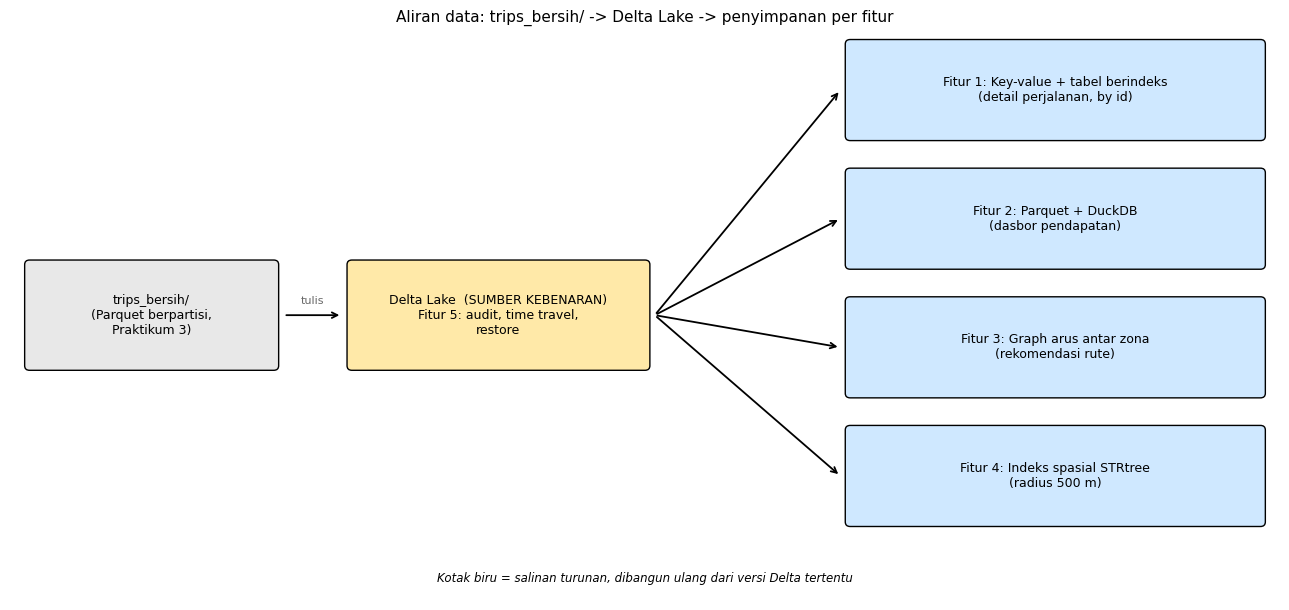

diagram disimpan: /content/drive/MyDrive/BigData/Praktikum4/diagram_aliran_data.png


In [85]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(13, 6.2))
ax.set_xlim(0, 13); ax.set_ylim(0, 6.2); ax.axis("off")

def kotak(x, y, w, h, teks, warna):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05", fc=warna, ec="black"))
    ax.text(x + w / 2, y + h / 2, teks, ha="center", va="center", fontsize=9)

def panah(x1, y1, x2, y2, label=""):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", lw=1.3))
    if label:
        ax.text((x1 + x2) / 2, (y1 + y2) / 2 + 0.12, label, ha="center", fontsize=8, color="dimgray")

kotak(0.2, 2.55, 2.5, 1.1, "trips_bersih/\n(Parquet berpartisi,\nPraktikum 3)", "#e8e8e8")
kotak(3.5, 2.55, 3.0, 1.1, "Delta Lake  (SUMBER KEBENARAN)\nFitur 5: audit, time travel,\nrestore", "#ffe9a8")
panah(2.8, 3.1, 3.4, 3.1, "tulis")

tujuan = [
    (5.15, "Fitur 1: Key-value + tabel berindeks\n(detail perjalanan, by id)"),
    (3.75, "Fitur 2: Parquet + DuckDB\n(dasbor pendapatan)"),
    (2.35, "Fitur 3: Graph arus antar zona\n(rekomendasi rute)"),
    (0.95, "Fitur 4: Indeks spasial STRtree\n(radius 500 m)"),
]
for y, teks in tujuan:
    kotak(8.6, y - 0.1, 4.2, 1.0, teks, "#cfe8ff")
    panah(6.6, 3.1, 8.5, y + 0.4)
ax.text(6.5, 0.2, "Kotak biru = salinan turunan, dibangun ulang dari versi Delta tertentu", ha="center", fontsize=8.5, style="italic")
ax.set_title("Aliran data: trips_bersih/ -> Delta Lake -> penyimpanan per fitur", fontsize=11)
plt.tight_layout()
plt.savefig(f"{DIR_SIMPAN}/diagram_aliran_data.png", dpi=150)
plt.show()
print("diagram disimpan:", f"{DIR_SIMPAN}/diagram_aliran_data.png")

##### P-3 — Paragraf: data ganda dan cara menjaganya tetap sama
**Bagian rancangan yang terpaksa menyimpan data ganda.** Pada rancangan ini hampir semua fitur menyimpan salinan sendiri dari data perjalanan: cache key-value (fitur 1), Parquet berpartisi untuk DuckDB (fitur 2), graph arus antar zona (fitur 3, ringkasan agregat), dan indeks spasial (fitur 4). Tabel Delta (fitur 5) adalah satu-satunya **sumber kebenaran**; semua yang lain adalah salinan turunan. Duplikasi ini harga yang dibayar agar tiap pertanyaan murah dijawab (embedding/denormalisasi), bukan kebetulan.

**Cara menjaga kedua salinan tetap sama.** (1) Semua penulisan dan koreksi hanya lewat Delta Lake; salinan turunan tidak pernah ditulis langsung (satu jalur tulis). (2) Tiap salinan dibangun ulang (atau diperbarui inkremental) dari *versi Delta tertentu* menurut jadwal, dan nomor versi sumbernya dicatat pada salinan itu sehingga ketahuan bila tertinggal. (3) Setelah tiap pembaruan dijalankan pemeriksaan rekonsiliasi: jumlah baris dan `SUM(total_bayar)` salinan harus sama dengan versi Delta yang dirujuk (seperti pengecekan "hasil sama?" pada K-2, K-4, dan K-5). (4) Bila koreksi keuangan dilakukan (UPDATE/RESTORE di Delta), salinan turunan wajib diperbarui dari versi baru; selama jeda itu data turunan boleh sesaat tertinggal (*eventually consistent*), tetapi fitur audit selalu membaca langsung dari Delta.

In [86]:
# Simpan laporan studi kasus (tabel + paragraf) ke Drive sebagai bahan laporan PDF
paragraf = """
## Data ganda dan cara menjaganya
Tabel Delta (fitur 5) adalah sumber kebenaran; cache key-value (fitur 1), Parquet berpartisi untuk DuckDB (fitur 2),
graph arus antar zona (fitur 3), dan indeks spasial (fitur 4) adalah salinan turunan. Penulisan hanya lewat Delta;
tiap salinan dibangun ulang dari versi Delta tertentu dan nomor versinya dicatat; rekonsiliasi jumlah baris dan
SUM(total_bayar) dijalankan setelah setiap pembaruan; setelah koreksi/RESTORE di Delta, salinan turunan diperbarui.
"""
with open(f"{DIR_SIMPAN}/laporan_studi_kasus.md", "w", encoding="utf-8") as f:
    f.write("# Laporan Studi Kasus - Rancangan Penyimpanan Aplikasi Taksi\n\n" + tabel_md + "\n" + paragraf)
print("tersimpan:", f"{DIR_SIMPAN}/laporan_studi_kasus.md")

tersimpan: /content/drive/MyDrive/BigData/Praktikum4/laporan_studi_kasus.md


**Interpretasi:** setiap fitur mendapat cara menyimpan yang berbeda karena pertanyaan utamanya berbeda — tidak ada satu penyimpanan yang menang untuk kelima fitur. Itulah inti *polyglot persistence*. Untuk laporan PDF 2–3 halaman: salin tabel + diagram + paragraf di atas ke dokumen (atau gunakan `laporan_studi_kasus.md` dan `diagram_aliran_data.png` di folder Praktikum4).

---
# Q. Latihan
Dikerjakan pada notebook yang sama, setelah K-8 (Latihan 6 dijalankan paling akhir).

### Latihan 1 — 2.000 id acak: tabel berindeks vs key-value
Ulangi pencarian K-2 dengan 2.000 id acak untuk tabel berindeks dan key-value saja; hitung waktu rata-rata per pencarian dalam mikrodetik.

In [87]:
random.seed(7)
id_2000 = random.sample(range(1, len(data) + 1), 2000)

def cari_sql_2000():
    cur = con.cursor()   # tabel sudah punya idx_id dari K-2
    return [cur.execute("SELECT * FROM perjalanan WHERE id_perjalanan = ?", (i,)).fetchone() for i in id_2000]

def cari_kv_2000():
    return [json.loads(kv[f"perjalanan:{i}"]) for i in id_2000]

ukur("L1 cari 2000 - SQL berindeks", cari_sql_2000)
ukur("L1 cari 2000 - key-value", cari_kv_2000)
us_sql = t("L1 cari 2000 - SQL berindeks") / 2000 * 1e6
us_kv = t("L1 cari 2000 - key-value") / 2000 * 1e6
print(f"rata-rata per pencarian -> SQL berindeks: {us_sql:,.1f} µs | key-value: {us_kv:,.1f} µs | rasio: {kali(us_sql, us_kv):.1f}×")

[L1 cari 2000 - SQL berindeks] 0.0361 s
[L1 cari 2000 - key-value] 0.0114 s
rata-rata per pencarian -> SQL berindeks: 18.1 µs | key-value: 5.7 µs | rasio: 3.2×


**Interpretasi:** keduanya berada pada orde mikrodetik per pencarian. Key-value sedikit lebih cepat (tanpa parsing SQL), tetapi selisih mutlaknya terlalu kecil untuk terasa — sejalan dengan O-1.

### Latihan 2 — Dokumen vs SQL untuk zona tujuan tertentu + "Tunai"
Hitung dokumen (K-3) dengan zona tujuan tertentu dan `metode_bayar = "Tunai"`, lalu hitung angka yang sama lewat SQL pada tabel di K-2. Apakah sama? Bila tidak, apa sebabnya?

In [88]:
# Pilih zona tujuan yang paling sering muncul untuk pembayaran Tunai pada 20.000 baris pertama
subset = sample.head(20_000)
ZONA_PILIH = int(subset.loc[subset["metode_bayar"] == "Tunai", "zona_tujuan"].mode().iloc[0])
print("zona tujuan yang dipakai:", ZONA_PILIH)

# (1) TinyDB (hanya 20.000 baris pertama + 1 dokumen tambahan di K-3)
n_doc = len(tabel.search((Q.tujuan.zona == ZONA_PILIH) & (Q.biaya.metode_bayar == "Tunai")))

# (2) SQL pada tabel K-2 (300.000 baris)
n_sql_penuh = con.execute("SELECT COUNT(*) FROM perjalanan WHERE zona_tujuan = ? AND metode_bayar = 'Tunai'", (ZONA_PILIH,)).fetchone()[0]

# (3) SQL dibatasi pada 20.000 baris yang sama dengan isi TinyDB
n_sql_20k = con.execute("SELECT COUNT(*) FROM perjalanan WHERE zona_tujuan = ? AND metode_bayar = 'Tunai' AND id_perjalanan <= 20000", (ZONA_PILIH,)).fetchone()[0]

print(f"TinyDB (20.000 dokumen)         : {n_doc}")
print(f"SQL (tabel 300.000 baris)       : {n_sql_penuh}")
print(f"SQL (hanya id <= 20.000)        : {n_sql_20k}")
print("sama dengan SQL penuh?", n_doc == n_sql_penuh, "| sama dengan SQL 20.000 baris?", n_doc == n_sql_20k)

zona tujuan yang dipakai: 237
TinyDB (20.000 dokumen)         : 163
SQL (tabel 300.000 baris)       : 2165
SQL (hanya id <= 20.000)        : 163
sama dengan SQL penuh? False | sama dengan SQL 20.000 baris? True


**Interpretasi:** angka dokumen **tidak sama** dengan SQL pada tabel penuh karena cakupan datanya berbeda — TinyDB hanya memuat 20.000 baris pertama (ditambah 1 dokumen buatan `999_999` yang bukan Tunai), sedangkan tabel SQL memuat 300.000 baris. Pada himpunan yang sama (SQL dibatasi `id_perjalanan <= 20000`) angkanya **sama**, jadi dua model menjawab pertanyaan yang sama dengan benar selama datanya sama.

### Latihan 3 — `SUM` satu kolom vs beberapa kolom pada DuckDB
Jalankan `SUM` atas satu kolom angka, lalu atas beberapa kolom angka sekaligus. Bandingkan waktunya dan jelaskan dengan *column pruning*.

In [89]:
def median_waktu(sql, n=5):
    w = []
    for _ in range(n):
        t0 = time.perf_counter(); con_d.sql(sql).fetchall(); w.append(time.perf_counter() - t0)
    return sorted(w)[len(w) // 2]

SQL_1 = "SELECT SUM(total_bayar) FROM perjalanan"
SQL_4 = "SELECT SUM(total_bayar), SUM(jarak_mil), SUM(zona_jemput), SUM(zona_tujuan) FROM perjalanan"
con_d.sql(SQL_1).fetchall()   # pemanasan (agar cache file tidak mengganggu perbandingan)
w1 = median_waktu(SQL_1); w4 = median_waktu(SQL_4)
catatan.append({"langkah": "L3 DuckDB SUM 1 kolom", "detik": round(w1, 4)})
catatan.append({"langkah": "L3 DuckDB SUM 4 kolom", "detik": round(w4, 4)})
print(f"SUM 1 kolom : {w1:.4f} s (median 5 kali)")
print(f"SUM 4 kolom : {w4:.4f} s (median 5 kali)")
print(f"rasio 4 kolom / 1 kolom = {kali(w4, w1):.2f}×")

SUM 1 kolom : 0.0609 s (median 5 kali)
SUM 4 kolom : 0.1327 s (median 5 kali)
rasio 4 kolom / 1 kolom = 2.18×


**Interpretasi:** waktu mengikuti **jumlah kolom yang dibaca**, bukan jumlah seluruh kolom di berkas. `SUM` satu kolom hanya membaca satu kolom dari Parquet; menambah kolom berarti menambah byte yang dibaca dan dihitung, sehingga waktunya naik. Keduanya tetap jauh lebih murah daripada membaca semua kolom (*column pruning*, Praktikum 3/K-4) — itulah keunggulan penyimpanan per kolom untuk agregasi.

### Latihan 4 — Lima zona dengan tujuan berbeda terbanyak (graph vs SQL)
Gunakan *out-degree* pada graph, lalu silangkan dengan SQL memakai `COUNT(DISTINCT tujuan)`.

In [90]:
# Cara graph: out-degree = jumlah tujuan berbeda dari tiap zona (urutan dibuat pasti: derajat desc, zona asc)
top_out = sorted(G.out_degree(), key=lambda kv_: (-kv_[1], kv_[0]))[:5]
print("graph (out-degree):", top_out)

# Cara SQL: COUNT(DISTINCT tujuan) per zona asal
top_out_sql = con_d.sql("""
    SELECT zona_jemput AS asal, COUNT(DISTINCT zona_tujuan) AS n_tujuan
    FROM perjalanan GROUP BY zona_jemput
    ORDER BY n_tujuan DESC, asal LIMIT 5""").fetchall()
print("SQL (COUNT DISTINCT):", [tuple(r_) for r_ in top_out_sql])
print("sama?", [tuple(x) for x in top_out] == [tuple(r_) for r_ in top_out_sql])

graph (out-degree): [(132, 260), (138, 254), (264, 241), (230, 234), (140, 233)]
SQL (COUNT DISTINCT): [(132, 260), (138, 254), (264, 241), (230, 234), (140, 233)]
sama? True


**Interpretasi:** out-degree pada graph sama dengan `COUNT(DISTINCT tujuan)` pada SQL (selama arus yang sama dipakai) — dua model, satu jawaban. Pengurut tambahan (derajat, zona) dipakai agar urutan seri pasti (lihat M.5).

### Latihan 5 — Ukuran kotak 0,02° dan 0,001°: STRtree vs NumPy
Ulangi pengukuran K-6 dengan sisi kotak 0,02 derajat dan 0,001 derajat (0,01° = baseline K-6). Bagaimana perbandingan STRtree terhadap NumPy berubah, dan mengapa kotak yang lebih kecil lebih menguntungkan indeks?

In [91]:
def uji_spasial(sisi):
    s = sisi / 2
    # NumPy tanpa indeks spasial
    t0 = time.perf_counter()
    hn = []
    for x, y in zip(cx, cy):
        m = (bujur >= x - s) & (bujur <= x + s) & (lintang >= y - s) & (lintang <= y + s)
        hn.append(int(m.sum()))
    t_np_ = time.perf_counter() - t0
    # STRtree: bangun lalu cari
    kt = [box(x - s, y - s, x + s, y + s) for x, y in zip(cx, cy)]
    t0 = time.perf_counter(); pohon_ = STRtree(titik); t_bangun_ = time.perf_counter() - t0
    t0 = time.perf_counter(); hi = [len(pohon_.query(k, predicate="contains")) for k in kt]; t_cari_ = time.perf_counter() - t0
    return {"sisi_derajat": sisi, "numpy_s": round(t_np_, 4), "strtree_cari_s": round(t_cari_, 4),
            "strtree_total_s": round(t_bangun_ + t_cari_, 4),
            "rasio_cari": round(kali(t_np_, t_cari_), 2), "rasio_total": round(kali(t_np_, t_bangun_ + t_cari_), 2),
            "titik_ditemukan": sum(hi), "hasil_sama": hn == hi}

hasil_l5 = pd.DataFrame([uji_spasial(s_) for s_ in (0.02, 0.01, 0.001)])
display(hasil_l5)

,sisi_derajat,numpy_s,strtree_cari_s,strtree_total_s,rasio_cari,rasio_total,titik_ditemukan,hasil_sama
0,0.020,0.5013,0.8015,0.8743,0.63,0.57,1666631,True
1,0.010,0.5140,0.2094,0.2634,2.46,1.95,417545,True
2,0.001,0.4946,0.0114,0.0655,43.43,7.56,4149,True


**Interpretasi:** pada kotak besar (0,02°) STRtree mengembalikan banyak titik per kotak sehingga keunggulannya terhadap NumPy mengecil; pada kotak sangat kecil (0,001°) rasio melonjak. Alasannya: **NumPy selalu memindai seluruh 200.000 titik** untuk tiap kotak berapa pun ukurannya (biaya tetap), sedangkan **STRtree hanya membuka cabang pohon yang bersinggungan dengan kotak** — makin kecil kotak, makin sedikit cabang dan titik yang disentuh. Jadi manfaat indeks makin besar saat kotak makin kecil dan titik makin banyak. (Kolom `hasil_sama` memastikan kedua cara menjawab sama.)

### Latihan 6 — `restore` vs time travel
Jalankan sel di bawah setelah K-8. Jelaskan perbedaan time travel (membaca versi lama) dengan restore (mengembalikan tabel ke versi lama), dan mengapa restore dicatat sebagai versi baru.

In [92]:
dt = DeltaTable(PATH_DELTA)
print("versi sebelum restore:", dt.version(), "| baris:", len(dt.to_pandas()))
dt.restore(1)   # kembalikan tabel ke keadaan versi 1 (dicatat sebagai versi baru)
dt = DeltaTable(PATH_DELTA)
print("versi setelah restore:", dt.version(), "| baris:", len(dt.to_pandas()))
print([h.get("operation") for h in dt.history()][:3])

versi sebelum restore: 23 | baris: 160000
versi setelah restore: 24 | baris: 150000
['RESTORE', 'OPTIMIZE', 'WRITE']


**Interpretasi:**
- **Time travel** hanya *membaca* keadaan lama (`DeltaTable(path, version=n)`); tabel "terkini" tidak berubah. **Restore** *mengubah* tabel terkini menjadi sama dengan versi lama.
- Restore dicatat sebagai **versi baru** (`RESTORE`), bukan menghapus riwayat, karena Delta bersifat *append-only* pada log: perubahan apa pun (termasuk membatalkan) adalah komit baru. Dengan begitu riwayat tetap utuh untuk audit, dan restore sendiri bisa dibatalkan dengan me-restore ke versi sebelumnya.

---
# R. Tugas Praktikum

### R-1. Rekap benchmark
Kumpulkan `benchmark_nosql.csv` dan tabel rekap K-9 yang sudah terisi, dengan satu kalimat interpretasi untuk tiap baris (kolom terakhir tabel).

In [93]:
pd.DataFrame(catatan).to_csv(f"{DIR_SIMPAN}/benchmark_nosql.csv", index=False)
tabel_rekap.to_csv(f"{DIR_SIMPAN}/tabel_rekap_k9.csv", index=False)
print("tersimpan: benchmark_nosql.csv dan tabel_rekap_k9.csv di", DIR_SIMPAN)
display(tabel_rekap[["Kebutuhan", "Cara yang unggul", "Angka saya", "Interpretasi (1 kalimat)"]])

tersimpan: benchmark_nosql.csv dan tabel_rekap_k9.csv di /content/drive/MyDrive/BigData/Praktikum4


,Kebutuhan,Cara yang unggul,Angka saya,Interpretasi (1 kalimat)
0,Ambil satu data lewat id,Key-value; tabel dengan indeks,200 pencarian: tanpa indeks 11.9798 s | berindeks 0.0194 s | key-value 0.0060 s,"Indeks mempercepat pencarian ±618×; setelah berindeks, tabel hampir setara key-value."
1,Menghitung / merangkum banyak baris,Per kolom (DuckDB pada Parquet),DuckDB 0.0834 s vs SQLite 7.6561 s (91.8×); SQL GROUP BY 1.1037 s vs key-value 1.2633 s (1.1×),"Penyimpanan per kolom hanya membaca kolom yang perlu, sedangkan key-value harus membuka setiap nilai."
2,Data dengan field opsional / berubah-ubah,Document,(kualitatif) 4050 dari 20001 dokumen tidak punya field tip; 1 dokumen membawa field cuaca tanpa ALTER TABLE,"Document menampung bentuk data yang beragam tanpa migrasi, dengan risiko validasi diserahkan ke aplikasi."
3,Keterhubungan dengan jumlah langkah bebas,Graph,"2 langkah: graph 0.0065 s | SQL 0.0075 s; jangkauan k=1..4: [74, 214, 214, 214] zona",Kecepatannya setara pada 263 zona; keunggulan graph ada pada kemudahan mengganti k tanpa menambah JOIN.
4,Mencari lokasi dalam wilayah,Spasial dengan indeks (STRtree),STRtree 0.216 s (+ bangun 0.061 s) | NumPy 0.478 s | loop 13.42 s untuk 5 kotak saja,"Terhadap loop selisihnya ribuan kali, terhadap NumPy hanya ±1.7×; pembanding menentukan klaim."
5,Perubahan yang harus aman dan bisa dibatalkan,Tabel Delta,(kualitatif) selisih total_bayar 25.0 = 25 baris dikoreksi; versi tetap 2 setelah kolom asing ditolak,Delta mencatat tiap perubahan sebagai versi sehingga bisa dibaca ulang/dikembalikan; folder Parquet biasa tidak.


### R-2. Data lain, cara lain — data "zona"
Data yang dipilih: **zona** (satu entitas: nomor zona, wilayah, jumlah jemputan, rata-rata bayar, dan zona tujuan teratasnya). Tiga cara menyimpan: **tabel (SQLite)**, **document (TinyDB)**, dan **graph (NetworkX)**. Untuk tiap cara ditulis satu pertanyaan yang mudah dan satu yang canggung.

##### R-2 (a) — Menyiapkan data zona

In [94]:
zona_stat = con_d.sql("""
    SELECT zona_jemput AS zona, ANY_VALUE(wilayah_jemput) AS wilayah,
           COUNT(*) AS n_jemput, ROUND(AVG(total_bayar), 2) AS rata_bayar
    FROM perjalanan GROUP BY zona_jemput""").df()
top3 = (arus.sort_values(["asal", "jumlah", "tujuan"], ascending=[True, False, True])
            .groupby("asal").head(3))
print("zona:", len(zona_stat), "| baris arus:", len(arus))
display(zona_stat.head(3))

zona: 254 | baris arus: 21583


,zona,wilayah,n_jemput,rata_bayar
0,60,Bronx,37,32.48
1,159,Bronx,121,24.00
2,168,Bronx,228,28.11


##### R-2 (b) — Cara 1: tabel (SQLite). Mudah: ranking rata-rata bayar. Canggung: zona yang dicapai tepat 3 langkah.

In [95]:
zona_db = sqlite3.connect(":memory:")
zona_stat.to_sql("zona", zona_db, index=False)
arus.to_sql("arus", zona_db, index=False)
zona_db.execute("CREATE INDEX i_asal ON arus(asal)")

# MUDAH: 5 zona dengan rata-rata bayar tertinggi (minimal 100 jemputan)
print("MUDAH  :", zona_db.execute("""SELECT zona, wilayah, rata_bayar FROM zona
                                     WHERE n_jemput >= 100 ORDER BY rata_bayar DESC, zona LIMIT 5""").fetchall())

# CANGGUNG: zona yang dicapai dalam tepat 3 langkah dari zona_awal -> 2 self-join
def tiga_langkah_sql():
    return zona_db.execute("""
        SELECT COUNT(DISTINCT a3.tujuan)
        FROM arus a1 JOIN arus a2 ON a1.tujuan = a2.asal
                     JOIN arus a3 ON a2.tujuan = a3.asal
        WHERE a1.asal = ?""", (int(zona_awal),)).fetchone()[0]
print("CANGGUNG (3 langkah, 2 self-join):", ukur("R2 tabel - 3 langkah SQL", tiga_langkah_sql), "zona")

MUDAH  : [(10, 'Queens', 87.72), (215, 'Queens', 81.18), (93, 'Queens', 79.47), (132, 'Queens', 77.33), (265, '__HIVE_DEFAULT_PARTITION__', 74.72)]
[R2 tabel - 3 langkah SQL] 1.2877 s
CANGGUNG (3 langkah, 2 self-join): 261 zona


##### R-2 (c) — Cara 2: document (TinyDB). Mudah: satu zona lengkap dalam satu baca. Canggung: "zona mana yang menuju zona X?"

In [96]:
db_zona = TinyDB(storage=MemoryStorage).table("zona")
top3_dict = {}
for a_, b_, c_ in zip(top3["asal"], top3["tujuan"], top3["jumlah"]):   # urutan sudah: jumlah terbesar dulu
    top3_dict.setdefault(int(a_), []).append({"zona": int(b_), "jumlah": int(c_)})
db_zona.insert_multiple([
    {"zona": int(r_.zona), "wilayah": r_.wilayah,
     "statistik": {"n_jemput": int(r_.n_jemput), "rata_bayar": float(r_.rata_bayar)},
     "top_tujuan": top3_dict.get(int(r_.zona), [])}
    for r_ in zona_stat.itertuples()])

# MUDAH: satu zona lengkap (wilayah, statistik, tujuan teratas) dalam SATU pembacaan
print("MUDAH  :", db_zona.get(Q.zona == int(zona_awal)))

# CANGGUNG: zona mana saja yang memiliki zona X sebagai salah satu tujuan teratas? (relasi terbalik -> pindai semua dokumen)
ZONA_X = int(top3_dict.get(int(zona_awal), [{"zona": int(zona_awal)}])[0]["zona"])
ke_x = db_zona.search(Q.top_tujuan.test(lambda lst: any(d["zona"] == ZONA_X for d in lst)))
print(f"CANGGUNG: {len(ke_x)} zona menempatkan zona {ZONA_X} di tujuan teratasnya (memindai {len(db_zona)} dokumen)")

MUDAH  : {'zona': 236, 'wilayah': 'Manhattan', 'statistik': {'n_jemput': 136276, 'rata_bayar': 20.64}, 'top_tujuan': [{'zona': 237, 'jumlah': 18810}, {'zona': 236, 'jumlah': 14110}, {'zona': 161, 'jumlah': 7497}]}
CANGGUNG: 13 zona menempatkan zona 237 di tujuan teratasnya (memindai 254 dokumen)


##### R-2 (d) — Cara 3: graph (NetworkX). Mudah: jangkauan k langkah. Canggung: rata-rata bayar per wilayah.

In [97]:
G2 = G.copy()
for r_ in zona_stat.itertuples():
    if int(r_.zona) in G2:
        G2.nodes[int(r_.zona)].update(wilayah=r_.wilayah, n_jemput=int(r_.n_jemput), rata_bayar=float(r_.rata_bayar))

# MUDAH: zona yang terjangkau dalam <= 3 langkah (cukup ganti k)
print("MUDAH  : zona dalam <= 3 langkah dari", zona_awal, "->", len(nx.single_source_shortest_path_length(H, zona_awal, cutoff=3)) - 1)

# CANGGUNG: rata-rata bayar per wilayah (agregasi tabel) -> harus berputar manual di semua node
def agregasi_graph():
    tot, jml = {}, {}
    for _, atr in G2.nodes(data=True):
        if "wilayah" in atr:
            tot[atr["wilayah"]] = tot.get(atr["wilayah"], 0) + atr["rata_bayar"] * atr["n_jemput"]
            jml[atr["wilayah"]] = jml.get(atr["wilayah"], 0) + atr["n_jemput"]
    return {w_: round(tot[w_] / jml[w_], 2) for w_ in tot}
print("CANGGUNG (agregasi manual di graph):", ukur("R2 graph - agregasi per wilayah", agregasi_graph))
print("pembanding SQL satu baris GROUP BY  :", dict(zip(hasil_d["wilayah_jemput"], hasil_d["rata_bayar"])))

MUDAH  : zona dalam <= 3 langkah dari 236 -> 214
[R2 graph - agregasi per wilayah] 0.0003 s
CANGGUNG (agregasi manual di graph): {'Bronx': 34.44, '__HIVE_DEFAULT_PARTITION__': 74.72, 'Manhattan': 22.72, 'Queens': 70.46, 'Brooklyn': 32.72, 'Staten Island': 74.07, 'Unknown': 39.24, 'EWR': 106.41}
pembanding SQL satu baris GROUP BY  : {'Manhattan': 22.72, 'Queens': 70.46, 'Unknown': 39.24, 'Brooklyn': 32.72, 'Bronx': 34.44, '__HIVE_DEFAULT_PARTITION__': 74.72, 'Staten Island': 74.07, 'EWR': 106.41}


##### R-2 (e) — Ringkasan rancangan
| Cara | Pertanyaan yang **mudah** | Pertanyaan yang **canggung** | Alasan |
|---|---|---|---|
| **Tabel (SQLite)** | Ranking zona berdasarkan rata-rata bayar (`ORDER BY`) | Zona yang dicapai tepat 3 langkah (2 self-join, makin banyak langkah makin panjang) | Tabel kuat untuk filter/agregasi, lemah untuk penelusuran relasi berantai |
| **Document (TinyDB)** | Satu zona lengkap (wilayah, statistik, tujuan teratas) dengan satu pembacaan | "Zona mana yang menuju zona X?" — relasi terbalik, harus memindai semua dokumen | Document cocok untuk satu objek utuh, lemah untuk hubungan banyak-ke-banyak |
| **Graph (NetworkX)** | Zona yang terjangkau dalam ≤ k langkah (cukup ganti k) | Rata-rata bayar per wilayah (agregasi) — harus berputar manual di semua node | Graph unggul pada keterhubungan, bukan pada perangkuman data tabel |

### R-3. Delta Lake dua hari
Simulasi dua hari kerja pada tabel terpisah `trips_delta_2hari/`: **hari 1** menulis sebagian data; **hari 2** menambah data dan mengoreksi beberapa baris. Lalu dibuktikan bahwa tabel dapat dibaca seperti keadaan di akhir hari pertama, dan isi `_delta_log/` dilampirkan.

##### R-3 (a) — Hari 1 dan hari 2

In [98]:
PATH_LOCAL_2HARI = "/content/trips_delta_2hari"
PATH_DRIVE_2HARI = f"{DIR_SIMPAN}/trips_delta_2hari"

if os.path.exists(PATH_LOCAL_2HARI):
    shutil.rmtree(PATH_LOCAL_2HARI)

# ===== HARI 1: tulis sebagian data secara lokal =====
hari1 = data_delta.iloc[:60_000]
write_deltalake(PATH_LOCAL_2HARI, hari1, mode="overwrite")
v_akhir_hari1 = DeltaTable(PATH_LOCAL_2HARI).version()
total_hari1 = hari1["total_bayar"].sum()
print(f"[akhir hari 1] versi {v_akhir_hari1} | baris {len(hari1):,} | total_bayar {total_hari1:,.2f}")

# ===== HARI 2: tambah data + koreksi beberapa baris =====
hari2 = data_delta.iloc[60_000:90_000]
write_deltalake(PATH_LOCAL_2HARI, hari2, mode="append")
gabung = data_delta.iloc[:90_000]
n_kor2 = int(((gabung["wilayah_jemput"] == "Queens") & (gabung["metode_bayar"] == "Tunai")).sum())
dt2 = DeltaTable(PATH_LOCAL_2HARI)
dt2.update(predicate="wilayah_jemput = 'Queens' AND metode_bayar = 'Tunai'",
           updates={"total_bayar": "total_bayar + 2.0"})
print(f"[akhir hari 2] versi {DeltaTable(PATH_LOCAL_2HARI).version()} | baris dikoreksi: {n_kor2:,}")

# Cadangkan hasil akhir ke Google Drive agar dapat diakses secara permanen
shutil.rmtree(PATH_DRIVE_2HARI, ignore_errors=True)
shutil.copytree(PATH_LOCAL_2HARI, PATH_DRIVE_2HARI)
print("Tabel Delta 2 Hari berhasil dicadangkan ke Google Drive!")

[akhir hari 1] versi 0 | baris 60,000 | total_bayar 1,640,898.93
[akhir hari 2] versi 2 | baris dikoreksi: 1,866
Tabel Delta 2 Hari berhasil dicadangkan ke Google Drive!


##### R-3 (b) — Membaca tabel seperti keadaan di akhir hari 1 (time travel)

In [99]:
akhir_h1 = DeltaTable(PATH_2HARI, version=v_akhir_hari1).to_pandas()
sekarang2 = DeltaTable(PATH_2HARI).to_pandas()
print(f"akhir hari 1 : {len(akhir_h1):,} baris | total_bayar {akhir_h1['total_bayar'].sum():,.2f}")
print(f"sekarang     : {len(sekarang2):,} baris | total_bayar {sekarang2['total_bayar'].sum():,.2f}")
print("akhir hari 1 persis sama dengan yang ditulis hari 1?",
      len(akhir_h1) == len(hari1) and np.isclose(akhir_h1["total_bayar"].sum(), total_hari1))
print("riwayat:", [(h.get("version"), h.get("operation")) for h in reversed(DeltaTable(PATH_2HARI).history())])

akhir hari 1 : 60,000 baris | total_bayar 1,640,898.93
sekarang     : 90,000 baris | total_bayar 2,459,290.31
akhir hari 1 persis sama dengan yang ditulis hari 1? True
riwayat: [(0, 'WRITE'), (1, 'WRITE'), (2, 'UPDATE')]


##### R-3 (c) — Isi `_delta_log/` (lampiran)
Tiap berkas JSON = satu komit. Aksi `add` menambah file Parquet ke tabel, `remove` mengeluarkannya, `commitInfo` mencatat operasi.

In [100]:
DIR_LOG = f"{PATH_2HARI}/_delta_log"
for nama in sorted(os.listdir(DIR_LOG)):
    if not nama.endswith(".json"):
        continue
    aksi = [json.loads(baris_) for baris_ in open(os.path.join(DIR_LOG, nama), encoding="utf-8") if baris_.strip()]
    ringkas = {}
    for a_ in aksi:
        kunci = next(iter(a_))
        ringkas[kunci] = ringkas.get(kunci, 0) + 1
    op = next((a_["commitInfo"].get("operation") for a_ in aksi if "commitInfo" in a_), "-")
    print(f"{nama} | operasi: {str(op):7s} | aksi: {ringkas}")

# Contoh isi mentah satu berkas log (versi 0), dipotong agar ringkas
print("\nContoh isi mentah", sorted(os.listdir(DIR_LOG))[0], ":")
for baris_ in open(os.path.join(DIR_LOG, sorted(os.listdir(DIR_LOG))[0]), encoding="utf-8"):
    print(" ", baris_.strip()[:200])

00000000000000000000.json | operasi: WRITE   | aksi: {'commitInfo': 1, 'protocol': 1, 'metaData': 1, 'add': 1}
00000000000000000001.json | operasi: WRITE   | aksi: {'commitInfo': 1, 'add': 1}
00000000000000000002.json | operasi: UPDATE  | aksi: {'commitInfo': 1, 'add': 1, 'remove': 2}

Contoh isi mentah 00000000000000000000.json :
  {"commitInfo":{"timestamp":1792154538266,"operation":"WRITE","operationParameters":{"mode":"Overwrite"},"engineInfo":"delta-rs:py-1.6.6","operationMetrics":{"num_added_files":1,"num_removed_files":0,"
  {"protocol":{"minReaderVersion":3,"minWriterVersion":7,"readerFeatures":["timestampNtz"],"writerFeatures":["timestampNtz"]}}
  {"metaData":{"id":"d8313429-683b-4dd9-b3bb-ef4591d2e872","name":null,"description":null,"format":{"provider":"parquet","options":{}},"schemaString":"{\"type\":\"struct\",\"fields\":[{\"name\":\"waktu_
  {"add":{"path":"part-00000-6931d9dc-6a38-4cea-8417-98e1800ce1b0-c000.snappy.parquet","partitionValues":{},"size":905574,"modificatio

**Interpretasi:** tabel pada akhir hari 1 (versi 0) tetap dapat dibaca persis seperti saat itu meski hari 2 sudah menambah dan mengoreksi data. Log menunjukkan versi 0 = `WRITE` (hari 1), versi 1 = `WRITE` (tambah data hari 2), versi 2 = `UPDATE` (koreksi, ditandai pasangan `remove` + `add`: file lama dikeluarkan, file baru ditambahkan). Folder `trips_delta_2hari/_delta_log/` di Drive adalah lampirannya.

### R-4. Laporan, pengemasan berkas, dan *Restart & Run all*
1. **Laporan PDF** rancangan penyimpanan studi kasus (Bagian P): tabel + diagram + paragraf data ganda (bahan: `laporan_studi_kasus.md`, `diagram_aliran_data.png`).
2. **Restart notebook and run all pada runtime bersih:** *Runtime → Restart session and run all*, pastikan tidak ada error.
3. **Berkas yang dikumpulkan:** notebook `.ipynb` (dengan output), `benchmark_nosql.csv`, arsip `trips_delta.zip`, laporan PDF.

Sel di bawah menyimpan ulang `benchmark_nosql.csv` (sudah termasuk ukuran dari latihan) dan membuat arsip `trips_delta.zip` (serta `trips_delta_2hari.zip`).

In [101]:
pd.DataFrame(catatan).to_csv(f"{DIR_SIMPAN}/benchmark_nosql.csv", index=False)
shutil.make_archive(f"{DIR_SIMPAN}/trips_delta", "zip", PATH_DELTA)
shutil.make_archive(f"{DIR_SIMPAN}/trips_delta_2hari", "zip", PATH_2HARI)

print("Isi folder Praktikum4:")
for nama in sorted(os.listdir(DIR_SIMPAN)):
    p = os.path.join(DIR_SIMPAN, nama)
    ukuran = os.path.getsize(p) / 1024**2 if os.path.isfile(p) else None
    print(f"  {nama:32s}", f"{ukuran:8.2f} MB" if ukuran is not None else "   (folder)")

Isi folder Praktikum4:
  benchmark_nosql.csv                  0.00 MB
  diagram_aliran_data.png              0.11 MB
  laporan_studi_kasus.md               0.00 MB
  tabel_rekap_k9.csv                   0.00 MB
  trips_delta                         (folder)
  trips_delta.zip                      5.70 MB
  trips_delta_2hari                   (folder)
  trips_delta_2hari.zip                2.26 MB


---
# S. Pertanyaan Evaluasi

**S-1. Mengapa NoSQL sering dibaca "Not Only SQL"? Sebutkan dua situasi ketika tabel relasional tetap pilihan yang lebih baik.**

NoSQL bukan pengganti SQL, melainkan **tambahan pilihan**: sistem sungguhan sering memakai beberapa jenis penyimpanan sekaligus (*polyglot persistence*), masing-masing untuk pekerjaan yang paling cocok baginya. Tabel relasional tetap lebih baik pada: (1) **transaksi yang menuntut integritas ketat (ACID) lintas banyak tabel**, mis. pembayaran, saldo, dan pembukuan, karena relasi, constraint, dan transaksi bawaannya matang; (2) **data berskema stabil dengan pertanyaan ad-hoc, `JOIN`, dan agregasi yang beragam**, selama data masih muat di satu mesin — SQL sangat ekspresif dan indeks membuat pencarian cepat (terbukti di K-2: tabel berindeks hampir secepat key-value).

**S-2. Apa perbedaan BASE dan ACID? Jelaskan teorema CAP dengan satu contoh data pada aplikasi taksi yang sebaiknya memilih consistency, dan satu yang boleh memilih availability.**

- **ACID** (*Atomicity, Consistency, Isolation, Durability*): transaksi berhasil seluruhnya atau tidak sama sekali, data selalu konsisten, dan hasilnya tahan lama. **BASE** (*Basically Available, Soft state, Eventually consistent*): mengutamakan ketersediaan dan kecepatan; kondisi data "akhirnya" seragam sehingga untuk sesaat pembaca bisa melihat data yang belum terbaru.
- **Teorema CAP:** saat jaringan antar mesin terputus (*partition*), sistem harus memilih **consistency** (semua pembaca melihat data terbaru yang sama, dengan konsekuensi sebagian permintaan ditolak/menunggu) atau **availability** (setiap permintaan tetap dijawab, dengan konsekuensi datanya mungkin belum terbaru).
- **Pilih consistency:** **saldo/pembayaran penumpang atau tarif yang ditagihkan** — angka yang salah atau ganda berarti kerugian uang. **Boleh availability:** **daftar "perjalanan terbaru" atau posisi taksi di sekitar** — tertinggal beberapa detik tidak merusak apa pun, dan lebih penting tetap tampil.

**S-3. Mengapa pencarian satu data pada key-value sangat cepat, tetapi menghitung sangat lambat? Apa yang dikorbankan key-value demi kesederhanaannya?**

Pencarian cepat karena **kunci langsung menunjukkan letak data** (seperti `dict`/tabel hash; seluruh data diatur di sekeliling kuncinya) — tidak ada penelusuran, sama seperti indeks (M.1). Menghitung lambat karena bagi penyimpan, **nilai hanyalah teks yang tak dikenal isinya**; untuk menghitung rata-rata, kode aplikasi harus membuka (`json.loads`) setiap nilai dan menghitung sendiri (M.2; lihat rasio di O-2). Yang dikorbankan: **kemampuan bertanya berdasarkan isi** — filter pada field, agregasi (`GROUP BY`), dan `JOIN` — sehingga semuanya harus dikerjakan di sisi aplikasi.

**S-4. Jelaskan perbedaan menyatukan data (embedding) dan merujuk (referencing) pada model document, dan satu kondisi yang membuat masing-masing lebih tepat.**

- **Embedding:** data terkait dibungkus di dalam satu dokumen (di K-3: zona dan wilayah ikut di dokumen perjalanan). Satu kali baca mendapat semuanya, tetapi datanya terduplikasi sehingga bila nama wilayah berubah, semua dokumen harus diperbarui. **Lebih tepat** bila data dibaca bersama-sama dan jarang berubah (mis. rincian biaya sebuah perjalanan).
- **Referencing:** dokumen hanya menyimpan id (mis. nomor zona) dan detailnya disimpan terpisah. Hemat dan mudah diperbarui, tetapi butuh pembacaan kedua untuk menampilkan detail. **Lebih tepat** bila data sering berubah atau dipakai banyak dokumen (mis. nama dan atribut zona yang dipakai jutaan perjalanan).

**S-5. Kapan graph lebih unggul dari SQL untuk pertanyaan keterhubungan? Berikan alasan yang tidak bergantung pada kecepatan.**

Graph unggul bila **keterhubungan dengan kedalaman bervariasi atau tidak diketahui** adalah inti pertanyaan (rute 2, 3, … k langkah, jalur terpendek, rekomendasi, jaringan sosial). Alasan non-kecepatan: (1) **ekspresivitas** — "paling banyak k langkah" cukup mengganti angka `k` (K-5), sedangkan SQL butuh satu `JOIN` per langkah sehingga query membengkak dan sulit dirawat; (2) **algoritma bawaan** (jalur terpendek, komponen terhubung, sentralitas) tersedia langsung; (3) **model data mencerminkan dunia nyata** — hubungan adalah bagian eksplisit dari data sehingga query lebih mudah dibaca dan diubah. Pada skala kecil (263 zona) kecepatannya setara, jadi alasan memilih graph adalah kemudahan bertanya, bukan kecepatan.

**S-6. Apa yang dilakukan indeks spasial sebelum memeriksa lokasi secara tepat? Mengapa klaim "indeks 1.000 kali lebih cepat" bisa menyesatkan?**

Indeks spasial (R-tree / `STRtree`) **mengelompokkan titik yang berdekatan ke dalam kotak berjenjang (bounding box)**. Saat mencari, kelompok yang kotaknya **tidak bersinggungan** dengan wilayah pencarian dilewati begitu saja; hanya kandidat yang tersisa yang diperiksa secara tepat (cara kerjanya mirip *partition pruning*, tetapi berdasarkan letak di peta). Klaim "1.000 kali lebih cepat" menyesatkan karena **besar percepatan bergantung pada pembandingnya**: terhadap loop Python selisihnya ribuan kali, tetapi terhadap NumPy (yang sudah vektorisasi) hanya beberapa kali (O-6). Klaim yang jujur harus menyebut pembanding, ukuran data, ukuran kotak, dan apakah waktu membangun indeks dihitung.

**S-7. Apa isi folder `_delta_log/` dan bagaimana ia membuat penulisan bersifat atomik dan time travel mungkin? Mengapa `VACUUM` dengan retention 0 jam berbahaya?**

`_delta_log/` berisi **catatan transaksi**: satu berkas JSON per komit (versi), berisi daftar file Parquet yang **ditambahkan** (`add`) dan **dikeluarkan** (`remove`) dari tabel serta metadata operasi (`commitInfo`); folder ini adalah sumber kebenaran, file Parquet hanyalah isinya. **Atomik:** satu komit adalah satu berkas yang ditulis sekaligus, sehingga pembaca melihat tabel sebelum atau sesudah komit, tidak pernah di tengahnya; penulisan yang gagal tidak menghasilkan komit (terbukti di K-7: versi tetap 2). **Time travel:** isi tabel pada versi *n* adalah hasil membaca log sampai berkas ke-*n*; karena `update`/`compact` tidak menimpa file lama (hanya mencatat penggantian), versi lama dapat direkonstruksi. **`VACUUM` retensi 0 jam berbahaya** karena menghapus secara fisik semua file yang tak lagi dipakai versi terkini — file yang mungkin masih dibaca proses lain ikut terhapus dan time travel ke versi lama terputus. Nilai bawaan (sekitar 7 hari) melindungi hal itu.